# Feature engineering and multivariate LSTM forecasting

## 1. Research objective and motivation

Feature engineering constructs useful representations of observations before a model learns its weights. In next-session NVIDIA forecasting, price-relative trends, momentum and broader market movements might expose structure that is difficult to learn from absolute prices alone. They might also add redundant inputs, estimation noise and capacity. Their value must therefore be tested rather than assumed.

- **RQ2:** Does the technical-indicator group improve next-session NVDA closing-price forecasts?
- **RQ3:** Do SPY and XLK returns add predictive value beyond that indicator group?

| Model | Session-level information | Controlled comparison |
|---|---|---|
| A | NVDA Close | Common-sample price-only reference |
| B | A + seven price-derived features | B − A tests the technical group |
| C | B + SPY and XLK one-session log returns | C − B tests context conditional on the technical group |

The target is **next-session Yahoo split-adjusted NVDA Close in USD**, predicted after the origin session closes. All variants use 30 feature rows per example, fit on eligible 2015–2022 targets and compare on the same 2023–2024 targets. **2025 remains reserved and is not loaded or evaluated.** Close is a retrospective vendor history, not a point-in-time trading simulation; volume is excluded.

This notebook executes the actual feature, preprocessing, model-inference and evaluation functions. The nine recorded fits supply training evidence; no new models are trained. **Milestone 6 Model A is a fresh common-sample control**, not the original Milestone 5 price-only result. Model labels A/B/C here describe feature sets; all use **Milestone 5 hyperparameter Configuration C**. See the [approved specification](../docs/FEATURE_EXPERIMENT_PROPOSAL.md), [experiment evidence](../docs/MILESTONE_6.md) and [environment instructions](../README.md#installation).

In [1]:
from pathlib import Path
from dataclasses import asdict
import hashlib
import inspect
import json
import math
import runpy
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown, Code

from market_forecasting.features import (
    calculate_features, seeded_ema, wilder_rsi, prepare_feature_dataset, VARIANTS, TECHNICAL,
)
from market_forecasting.preprocessing import Standardisation, reconstruct_prices
from market_forecasting.dataset import error_metrics
from market_forecasting.calendar import audit_sessions
from market_forecasting.lstm import configure_runtime, predict_standardised, build_model
configure_runtime()
import tensorflow as tf

ROOT = Path.cwd() if (Path.cwd()/"configs/nvda.json").exists() else Path.cwd().parent
BASE = ROOT / "artifacts/features_v1"
config = json.loads((ROOT/"configs/nvda.json").read_text())
protocol = json.loads((ROOT/"configs/feature_experiment_v1.json").read_text())
selected = json.loads((ROOT/"configs/lstm_selected_v1.json").read_text())
results = json.loads((ROOT/"docs/feature_results_v1.json").read_text())
runs = json.loads((BASE/"runs.json").read_text())
provenance = json.loads((BASE/"provenance.json").read_text())
assert protocol["variants"] == VARIANTS
assert len(TECHNICAL) == 7 and {v:len(n) for v,n in VARIANTS.items()} == {"A":1,"B":8,"C":10}
assert len(runs) == results["attempts"] == 9 and results["failed_attempts"] == 0
assert not results["test_evaluated"] and all(r["status"]=="complete" and not r["test_evaluated"] for r in runs)
assert provenance == results["provenance"]
assert hashlib.sha256((ROOT/"configs/feature_experiment_v1.json").read_bytes()).hexdigest() == provenance["feature_config_sha256"]
assert hashlib.sha256((ROOT/"configs/lstm_selected_v1.json").read_bytes()).hexdigest() == provenance["selected_config_sha256"]

COLORS = {"A":"#2563eb", "B":"#c56b12", "C":"#168269"}
SEEDS = protocol["seeds"]
SEED_COLORS = dict(zip(SEEDS,["#2563eb","#c56b12","#168269"]))
plt.rcParams.update({"figure.dpi":110,"font.size":10,"axes.spines.top":False,
                     "axes.spines.right":False,"axes.grid":True,"grid.alpha":.18})
pd.options.display.float_format = "{:,.6f}".format

def date_axis(ax, sessions=None):
    """Keep session dates readable on time-series panels."""
    if sessions is not None:
        ax.set_xlim(sessions.min(),sessions.max())
    locator=mdates.AutoDateLocator(minticks=4,maxticks=7)
    ax.xaxis.set_major_locator(locator);ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

# Import the real stage loader without invoking its training command.
load_stage = runpy.run_path(str(ROOT/"scripts/run_lstm_experiments.py"))["load_stage"]
series, calendar_rows = {}, []
for ticker in ("NVDA","SPY","XLK"):
    series[ticker], digest = load_stage(dict(config,target_ticker=ticker),config["validation_end"])
    assert digest == provenance["snapshot_sha256"][ticker]
    calendar = "NASDAQ" if ticker=="NVDA" else "NYSE"
    audit = audit_sessions(series[ticker].index,config["start"],config["validation_end"],calendar)
    assert not audit["missing"] and not audit["unexpected"] and not audit["duplicate_dates"] and audit["ordered"]
    calendar_rows.append({"ticker":ticker,"calendar":calendar,"rows":len(series[ticker]),
                          "first session":series[ticker].index.min(),"last session":series[ticker].index.max(),
                          "missing sessions":len(audit["missing"]),"unexpected sessions":len(audit["unexpected"])})
raw, features = calculate_features(series,config)
assert raw.index.max() <= pd.Timestamp(config["validation_end"])
display(pd.DataFrame(calendar_rows))
print("Nine recorded fits; bounded snapshot access; no training in this notebook.")

,ticker,calendar,rows,first session,last session,missing sessions,unexpected sessions
0,NVDA,NASDAQ,2516,2015-01-02,2024-12-31,0,0
1,SPY,NYSE,2516,2015-01-02,2024-12-31,0,0
2,XLK,NYSE,2516,2015-01-02,2024-12-31,0,0


Nine recorded fits; bounded snapshot access; no training in this notebook.


## 2. Understanding feature engineering

A feature is an input available when a forecast is issued. The **raw** input is NVDA Close. **Derived technical features** summarise its past levels and changes. **External context** comes from observed SPY/XLK closes transformed into returns. The **target**, next-session NVDA Close or its dollar correction, is a future label used for learning and evaluation; it is not an input feature.

Technical indicators introduce no independent NVDA data source. They reorganise historical observations into smoothing, relative-distance and momentum summaries. This may help a finite network or introduce redundant representations. Importantly, they can also carry **older history than Model A's 30 closes**: a 30-row SMA50 sequence spans 79 source closes, and recursive EMA/RSI states can retain earlier history. Equal tensor length does not mean equal effective historical context. This is causal feature engineering, not future leakage.

The table below distinguishes raw indicator values from the dimensionless values actually supplied to preprocessing. Normalisation defines the feature; standardisation, performed later, learns training-only means and scales. These are separate operations.

In [2]:
feature_definitions = {
    "close": ("Raw input", "NVDA Close", "USD"),
    "sma20_distance": ("Technical", "Close / SMA20 - 1", "ratio"),
    "sma50_distance": ("Technical", "Close / SMA50 - 1", "ratio"),
    "ema12_distance": ("Technical", "Close / EMA12 - 1", "ratio"),
    "ema26_distance": ("Technical", "Close / EMA26 - 1", "ratio"),
    "rsi14_fraction": ("Technical", "RSI14 / 100", "fraction"),
    "macd_relative": ("Technical", "MACD / Close", "ratio"),
    "histogram_relative": ("Technical", "Histogram / Close", "ratio"),
    "spy_log_return": ("Market context", "log(SPY Close / previous SPY Close)", "log return"),
    "xlk_log_return": ("Market context", "log(XLK Close / previous XLK Close)", "log return"),
}
display(pd.DataFrame([{"feature":name,"type":feature_definitions[name][0],
                       "definition":feature_definitions[name][1],"unscaled units":feature_definitions[name][2],
                       "models":", ".join(v for v,names in VARIANTS.items() if name in names)}
                      for name in VARIANTS["C"]]))
train_raw = raw.loc[:config["train_end"]]
train_features = features.loc[:config["train_end"]]
view = train_raw.loc["2022-01-01":]
print("Indicator illustrations below use training observations only.")

,feature,type,definition,unscaled units,models
0,close,Raw input,NVDA Close,USD,"A, B, C"
1,sma20_distance,Technical,Close / SMA20 - 1,ratio,"B, C"
2,sma50_distance,Technical,Close / SMA50 - 1,ratio,"B, C"
3,ema12_distance,Technical,Close / EMA12 - 1,ratio,"B, C"
4,ema26_distance,Technical,Close / EMA26 - 1,ratio,"B, C"
5,rsi14_fraction,Technical,RSI14 / 100,fraction,"B, C"
6,macd_relative,Technical,MACD / Close,ratio,"B, C"
7,histogram_relative,Technical,Histogram / Close,ratio,"B, C"
8,spy_log_return,Market context,log(SPY Close / previous SPY Close),log return,C
9,xlk_log_return,Market context,log(XLK Close / previous XLK Close),log return,C


Indicator illustrations below use training observations only.


## 3. Simple moving averages

An SMA assigns equal weight to the last \(n\) observed closes, including the current close:
\[
SMA_{n,t}=\frac{1}{n}\sum_{i=0}^{n-1}C_{t-i}.
\]
For closes 10, 12 and 14, the three-session mean is 12. Dropping 10 and adding 16 gives 14. This small arithmetic example illustrates a rolling window; the project actually uses **20 and 50 sessions** through `calculate_features()` and pandas `rolling(..., min_periods=n)`. No value exists before the full lookback is available. Longer windows generally smooth more and respond more slowly. [SMA reference](https://www.fidelity.com/learning-center/trading-investing/technical-analysis/technical-indicator-guide/sma).

The input is \(C_t/SMA_{n,t}-1\), not the SMA's dollar level. A value of 0.05 means Close is 5% above the trailing mean, not a forecast of a 5% rise. The mean includes the origin close because forecasts are formed **after** that session closes. Centring the window would improperly use later observations.

,illustrative window,arithmetic mean
0,"10, 12, 14",12.000000
1,"12, 14, 16",14.000000


,period,session,first source session,sum / n,implemented SMA USD,relative distance
0,20,2015-01-30,2015-01-02,0.496150,0.496150,-0.032551
1,20,2015-02-02,2015-01-05,0.495513,0.495513,-0.010116
2,50,2015-03-16,2015-01-02,0.526895,0.526895,0.089876
3,50,2015-03-17,2015-01-05,0.528455,0.528455,0.099904


,close,sma20,sma50,sma20_distance,sma50_distance
2022-01-03,30.121000,29.717150,29.446480,0.013590,0.022907
2022-01-04,29.290001,29.679800,29.577760,-0.013133,-0.009729
2022-01-05,27.604000,29.438650,29.666520,-0.062321,-0.069523
2022-01-06,28.177999,29.256250,29.735740,-0.036855,-0.052386
2022-01-07,27.247000,29.094100,29.791660,-0.063487,-0.085415


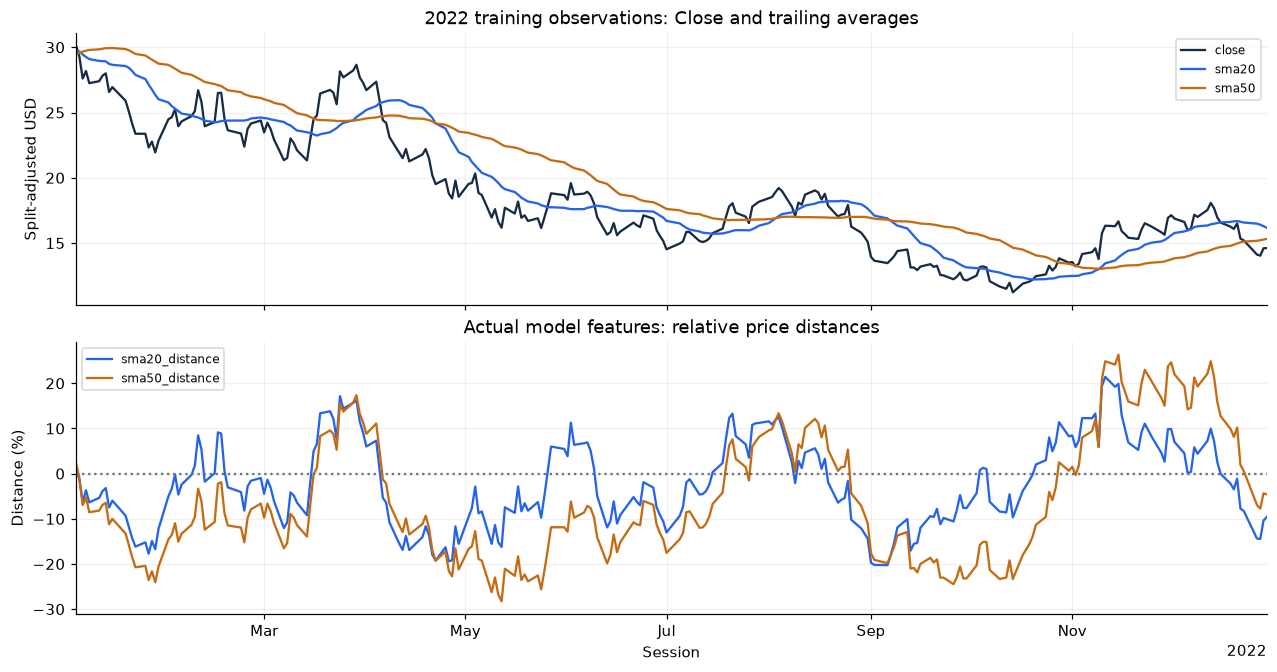

In [3]:
display(pd.DataFrame({"illustrative window":["10, 12, 14","12, 14, 16"],
                      "arithmetic mean":[(10+12+14)/3,(12+14+16)/3]}))
sma_checks=[]
for n in (20,50):
    # Direct sums verify two actual windows; the production function supplies the full series.
    for position in (n-1,n):
        observed=series["NVDA"].iloc[position-n+1:position+1]
        manual=float(observed.sum()/n)
        implemented=float(raw[f"sma{n}"].iloc[position])
        np.testing.assert_allclose(manual,implemented,rtol=0,atol=1e-12)
        sma_checks.append({"period":n,"session":raw.index[position],"first source session":observed.index[0],
                           "sum / n":manual,"implemented SMA USD":implemented,
                           "relative distance":features[f"sma{n}_distance"].iloc[position]})
display(pd.DataFrame(sma_checks))
display(view[["close","sma20","sma50"]].head().join(train_features[["sma20_distance","sma50_distance"]]))
fig,axes=plt.subplots(2,1,figsize=(11.5,6),layout="constrained",sharex=True)
for name,color in [("close","#172b45"),("sma20",COLORS["A"]),("sma50",COLORS["B"])]:
    axes[0].plot(view.index,view[name],label=name,color=color)
for name,color in [("sma20_distance",COLORS["A"]),("sma50_distance",COLORS["B"])]:
    axes[1].plot(view.index,train_features.loc[view.index,name]*100,label=name,color=color)
axes[0].set(title="2022 training observations: Close and trailing averages",ylabel="Split-adjusted USD")
axes[1].set(title="Actual model features: relative price distances",ylabel="Distance (%)",xlabel="Session")
axes[1].axhline(0,color="#64748b",ls=":")
for ax in axes:ax.legend(fontsize=8)
date_axis(axes[-1],view.index);plt.show()

The curves summarise past price location and smoothing lag; their separation is not a measure of future forecasting accuracy. The table verifies the first valid SMA values without filling the unavailable prefix. Both distances are dimensionless, but can still change distribution across market periods.

## 4. Exponential moving averages

The EMA gives greater weight to recent observations through a recursion:
\[
E_t=\alpha C_t+(1-\alpha)E_{t-1},\qquad\alpha=\frac{2}{n+1}.
\]
Our EMA12 and EMA26 use \(\alpha=2/13\) and \(2/27\). The first EMA is the **arithmetic mean of the first n closes**; earlier entries remain missing. This differs from initialising at the first close or using another library's default `ewm()` convention. The retained effect of the seed decays, rather than disappearing at a fixed date. [EMA reference](https://www.fidelity.com/learning-center/trading-investing/technical-analysis/technical-indicator-guide/ema).

For a three-period illustration with values 2, 4, 9, 8, 12, the seed is 5, then \(0.5(8)+0.5(5)=6.5\), followed by 9.25. The actual 12/26-period model features are \(C_t/E_t-1\). An EMA has recursive history, whereas an SMA discards the oldest observation after a fixed window.

def seeded_ema(values, period):
    """Seed an EMA with the first period's mean, retaining its missing prefix."""
    values = np.asarray(values, dtype=float)
    result = np.full(len(values), np.nan)
    valid = np.flatnonzero(np.isfinite(values))
    if not len(valid):
        return result
    start = int(valid[0])
    if not np.isfinite(values[start:]).all():
        raise ValueError("EMA input has an internal missing value")
    if len(values) - start < period:
        return result
    first = start + period - 1
    result[first] = values[start:first + 1].mean()
    alpha = 2 / (period + 1)
    for i in range(first + 1, len(values)):
        result[i] = alpha * values[i] + (1 - alpha) * result[i - 1]
    return result

,toy Close,EMA3
0,2,NaN
1,4,NaN
2,9,5.000000
3,8,6.500000
4,12,9.250000


,period,alpha,seed session,seed USD,next EMA USD
0,12,0.153846,2015-01-20,0.493167,0.495372
1,26,0.074074,2015-02-09,0.498154,0.500050


,close,ema12,ema26,ema12_distance,ema26_distance
2022-01-03,30.121000,29.764890,29.701218,0.011964,0.014134
2022-01-04,29.290001,29.691831,29.670757,-0.013533,-0.012833
2022-01-05,27.604000,29.370626,29.517664,-0.060149,-0.064831
2022-01-06,28.177999,29.187145,29.418430,-0.034575,-0.042165
2022-01-07,27.247000,28.888661,29.257583,-0.056827,-0.068720


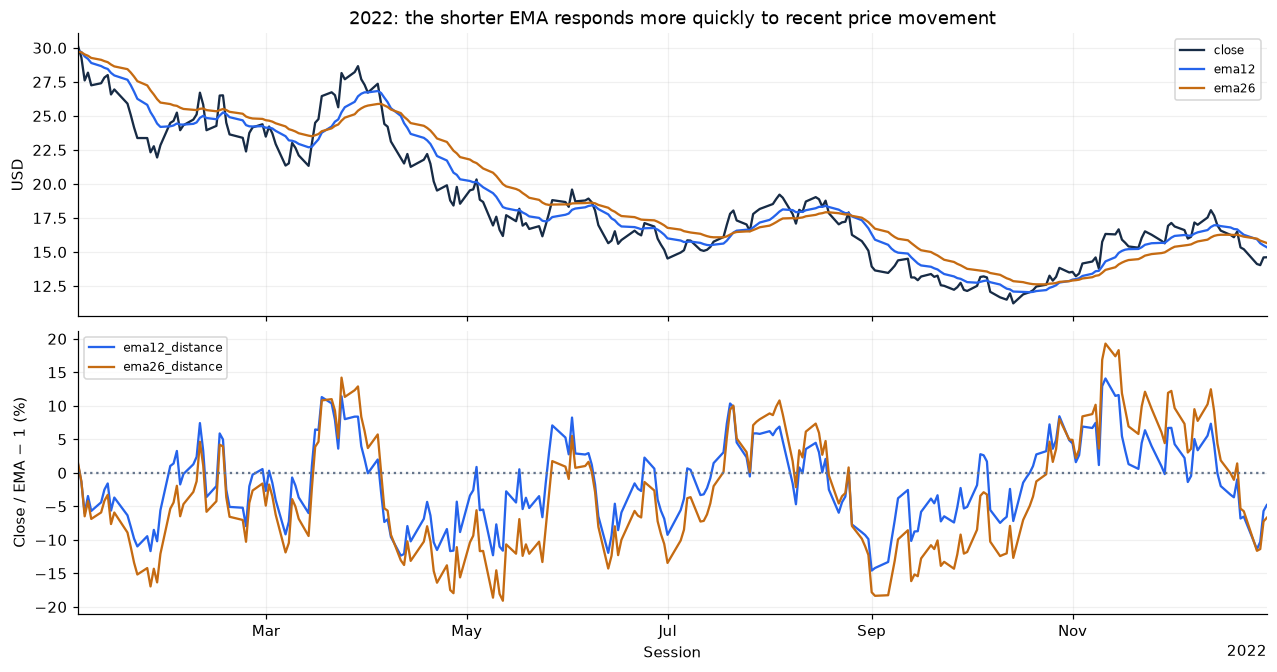

In [4]:
display(Code(inspect.getsource(seeded_ema),language="python"))
toy_ema=seeded_ema([2,4,9,8,12],3)
np.testing.assert_allclose(toy_ema[2:],[5.,6.5,9.25])
assert np.isnan(toy_ema[:2]).all()
display(pd.DataFrame({"toy Close":[2,4,9,8,12],"EMA3":toy_ema}))
ema_checks=[]
for n in (12,26):
    seed=series["NVDA"].iloc[:n].mean()
    alpha=2/(n+1)
    next_ema=alpha*series["NVDA"].iloc[n]+(1-alpha)*seed
    np.testing.assert_allclose(raw[f"ema{n}"].iloc[n-1:n+1],[seed,next_ema],rtol=0,atol=1e-12)
    ema_checks.append({"period":n,"alpha":alpha,"seed session":raw.index[n-1],
                       "seed USD":seed,"next EMA USD":next_ema})
display(pd.DataFrame(ema_checks))
display(view[["close","ema12","ema26"]].head().join(train_features[["ema12_distance","ema26_distance"]]))
fig,axes=plt.subplots(2,1,figsize=(11.5,6),layout="constrained",sharex=True)
for name,color in [("close","#172b45"),("ema12",COLORS["A"]),("ema26",COLORS["B"])]:
    axes[0].plot(view.index,view[name],color=color,label=name)
for name,color in [("ema12_distance",COLORS["A"]),("ema26_distance",COLORS["B"])]:
    axes[1].plot(view.index,train_features.loc[view.index,name]*100,color=color,label=name)
axes[0].set(title="2022: the shorter EMA responds more quickly to recent price movement",ylabel="USD")
axes[1].set(ylabel="Close / EMA − 1 (%)",xlabel="Session");axes[1].axhline(0,color="#64748b",ls=":")
for ax in axes:ax.legend(fontsize=8)
date_axis(axes[-1],view.index);plt.show()

## 5. Relative Strength Index

RSI describes the balance of recent upward and downward **dollar changes**, not the price's rank within a high/low range. Define \(d_t=C_t-C_{t-1}\), \(g_t=\max(d_t,0)\), \(\ell_t=\max(-d_t,0)\). The first average gain \(G\) and loss \(L\) are the means of 14 changes (requiring 15 closes). Wilder smoothing then gives
\[
G_t=\frac{13G_{t-1}+g_t}{14},\quad L_t=\frac{13L_{t-1}+\ell_t}{14},\quad
RS=G_t/L_t,\quad RSI_t=100-\frac{100}{1+RS}.
\]
For nonnegative gains/losses this is equivalently \(100G_t/(G_t+L_t)\). That is the implemented expression, with explicit edges: positive gain and zero loss gives 100; zero gain and positive loss gives 0; both zero gives neutral 50. The model receives **RSI/100**, then training-only standardisation—not raw RSI.

Levels 30 and 70 are conventional technical-analysis references, not learned thresholds or evidence of a profitable reversal. RSI can remain high or low during persistent movement. [RSI reference](https://www.fidelity.com/learning-center/trading-investing/technical-analysis/technical-indicator-guide/RSI).

def wilder_rsi(close, period=14):
    """Calculate RSI using an arithmetic seed and Wilder's recursive smoothing."""
    values = np.asarray(close, dtype=float)
    result = np.full(len(values), np.nan)
    if len(values) <= period:
        return result
    changes = np.diff(values)
    gains, losses = np.maximum(changes, 0), np.maximum(-changes, 0)
    gain, loss = gains[:period].mean(), losses[:period].mean()
    for i in range(period, len(values)):
        if i > period:
            gain = ((period - 1) * gain + gains[i - 1]) / period
            loss = ((period - 1) * loss + losses[i - 1]) / period
        # Flat prices are neutral; one-sided changes have defined extreme values.
        result[i] = 50 if gain == loss == 0 else (100 if loss == 0 else 100 * gain / (gain + loss))
    return result

,step,average gain,average loss,RSI3
0,First 3 changes,1.000000,0.333333,75.000000
1,Next change: -1,0.666667,0.555556,54.545455


,session,average gain,average loss,manual RSI14,implemented RSI14
0,2015-01-23,0.003554,0.002518,58.529427,58.529427
1,2015-01-26,0.003300,0.002499,56.907174,56.907174


,case,RSI
0,Only gains,100.000000
1,Only losses,0.000000
2,Flat,50.000000


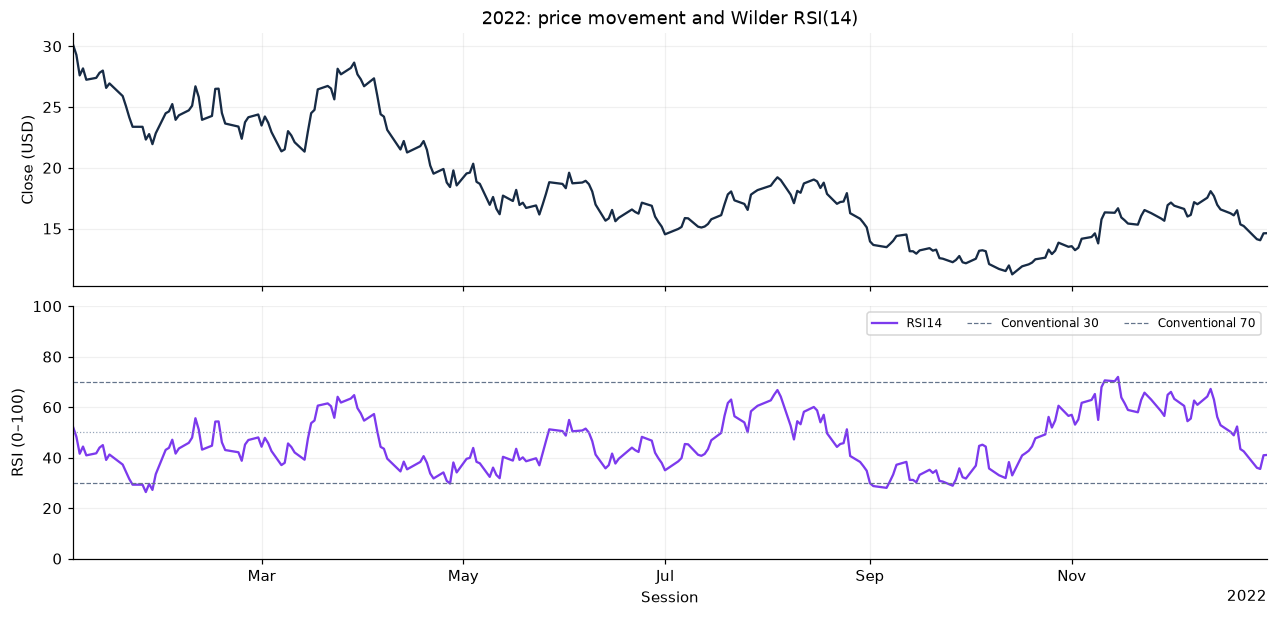

In [5]:
display(Code(inspect.getsource(wilder_rsi),language="python"))
# A three-change arithmetic illustration makes the seed and next Wilder update visible.
toy_prices=[10.,11.,10.,12.,11.]
gain,loss=(1+0+2)/3,(0+1+0)/3
next_gain,next_loss=(2*gain+0)/3,(2*loss+1)/3
toy_expected=[100*gain/(gain+loss),100*next_gain/(next_gain+next_loss)]
np.testing.assert_allclose(wilder_rsi(toy_prices,3)[3:],toy_expected)
display(pd.DataFrame({"step":["First 3 changes","Next change: -1"],"average gain":[gain,next_gain],
                      "average loss":[loss,next_loss],"RSI3":toy_expected}))
first_changes=np.diff(series["NVDA"].iloc[:16].to_numpy())
gains,losses=np.maximum(first_changes,0),np.maximum(-first_changes,0)
G,L=gains[:14].mean(),losses[:14].mean()
G_next,L_next=(13*G+gains[14])/14,(13*L+losses[14])/14
expected=np.array([100*G/(G+L),100*G_next/(G_next+L_next)])
np.testing.assert_allclose(raw.rsi14.iloc[14:16],expected,rtol=0,atol=1e-12)
display(pd.DataFrame({"session":raw.index[14:16],"average gain":[G,G_next],"average loss":[L,L_next],
                      "manual RSI14":expected,"implemented RSI14":raw.rsi14.iloc[14:16].to_numpy()}))
edge_rows=[]
for label,prices,value in [("Only gains",np.arange(1.,31.),100.),("Only losses",np.arange(30.,0.,-1),0.),("Flat",np.ones(30),50.)]:
    computed=wilder_rsi(prices)[14:]
    np.testing.assert_array_equal(computed,np.full(len(computed),value))
    edge_rows.append({"case":label,"RSI":computed[0]})
display(pd.DataFrame(edge_rows))
assert raw.rsi14.dropna().between(0,100).all()
np.testing.assert_allclose(features.rsi14_fraction,raw.rsi14/100,equal_nan=True)
fig,axes=plt.subplots(2,1,figsize=(11.5,5.5),sharex=True,layout="constrained")
axes[0].plot(view.index,view.close,color="#172b45");axes[0].set(ylabel="Close (USD)",title="2022: price movement and Wilder RSI(14)")
axes[1].plot(view.index,view.rsi14,color="#7c3aed",label="RSI14")
for level in (30,70):axes[1].axhline(level,color="#64748b",ls="--",lw=.8,label=f"Conventional {level}")
axes[1].axhline(50,color="#94a3b8",ls=":",lw=.8)
axes[1].set(ylabel="RSI (0–100)",ylim=(0,100),xlabel="Session");axes[1].legend(ncol=3,fontsize=8)
date_axis(axes[-1],view.index);plt.show()

The manual seed/update and synthetic edge cases agree with the actual function. RSI's bounded raw range does not make its standardised input bounded between zero and one; the subsequent transform measures deviations from its training distribution. The chart establishes indicator behaviour, not predictive value.

## 6. MACD: moving-average separation and momentum

The approved MACD(12,26,9) calculations are
\[
M_t=EMA_{12,t}-EMA_{26,t},\quad S_t=EMA_9(M)_t,\quad H_t=M_t-S_t.
\]
The signal starts from the mean of the first nine valid MACD values. With the stated EMA seeds, MACD first appears at source observation 26; the signal and histogram appear at observation 34. A positive histogram means MACD is above its signal, not necessarily that the next closing price will rise. [MACD reference](https://www.fidelity.com/learning-center/trading-investing/technical-analysis/technical-indicator-guide/macd).

Model B includes **`macd_relative = M/Close`** and **`histogram_relative = H/Close`**. The signal is computed for analysis but is not a separate input because \(S=M-H\). These are price-derived quantities; they are unrelated to the moving-average innovation term in ARIMA.

,close,ema12,ema26,macd,signal,histogram,macd_relative,histogram_relative
2015-02-09,0.509500,0.502355,0.498154,0.004201,NaN,NaN,0.008246,NaN
2015-02-10,0.523750,0.505647,0.500050,0.005597,NaN,NaN,0.010686,NaN
2015-02-11,0.520250,0.507893,0.501546,0.006347,NaN,NaN,0.012200,NaN
2015-02-12,0.557500,0.515525,0.505691,0.009834,NaN,NaN,0.017640,NaN
2015-02-13,0.557750,0.522021,0.509547,0.012474,NaN,NaN,0.022365,NaN
2015-02-17,0.559500,0.527787,0.513247,0.014540,NaN,NaN,0.025987,NaN
2015-02-18,0.553000,0.531666,0.516192,0.015474,NaN,NaN,0.027982,NaN
2015-02-19,0.554500,0.535179,0.519030,0.016149,NaN,NaN,0.029124,NaN
2015-02-20,0.558500,0.538767,0.521953,0.016814,0.011270,0.005543,0.030105,0.009926
2015-02-23,0.554000,0.541110,0.524327,0.016783,0.012373,0.004411,0.030295,0.007961


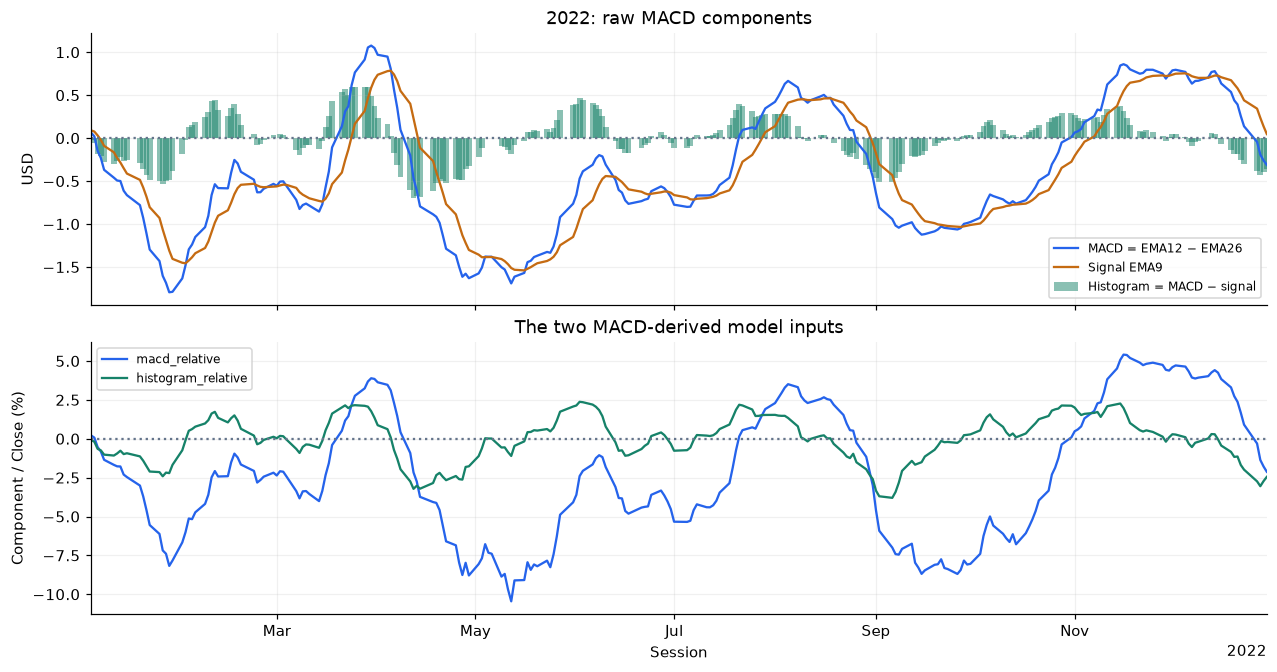

In [6]:
macd_seed=raw.ema12-raw.ema26
np.testing.assert_allclose(raw.macd,macd_seed,equal_nan=True)
first_signal=raw.macd.iloc[25:34].mean()
next_signal=(2/10)*raw.macd.iloc[34]+(8/10)*first_signal
np.testing.assert_allclose(raw.signal.iloc[33:35],[first_signal,next_signal],rtol=0,atol=1e-12)
np.testing.assert_allclose(raw.histogram,raw.macd-raw.signal,equal_nan=True)
np.testing.assert_allclose(features.macd_relative,raw.macd/raw.close,equal_nan=True)
np.testing.assert_allclose(features.histogram_relative,raw.histogram/raw.close,equal_nan=True)
assert "signal" not in VARIANTS["B"] and "signal_relative" not in VARIANTS["B"]
display(raw.iloc[25:35][["close","ema12","ema26","macd","signal","histogram"]].join(
    features[["macd_relative","histogram_relative"]]))
fig,axes=plt.subplots(2,1,figsize=(11.5,6),sharex=True,layout="constrained")
axes[0].plot(view.index,view.macd,color=COLORS["A"],label="MACD = EMA12 − EMA26")
axes[0].plot(view.index,view.signal,color=COLORS["B"],label="Signal EMA9")
axes[0].bar(view.index,view.histogram,width=1.8,color=COLORS["C"],alpha=.5,label="Histogram = MACD − signal")
axes[0].set(ylabel="USD",title="2022: raw MACD components")
for name,color in [("macd_relative",COLORS["A"]),("histogram_relative",COLORS["C"])]:
    axes[1].plot(view.index,train_features.loc[view.index,name]*100,color=color,label=name)
axes[1].set(ylabel="Component / Close (%)",xlabel="Session",title="The two MACD-derived model inputs")
for ax in axes:ax.axhline(0,color="#64748b",ls=":");ax.legend(fontsize=8)
date_axis(axes[-1],view.index);plt.show()

## 7. Broader market context: SPY and XLK

SPY represents broad US large-cap equity-market exposure through the S&P 500; XLK represents its technology-sector exposure. Their issuer-defined objectives support these roles: [SPY](https://www.ssga.com/us/en/institutional/etfs/state-street-spdr-sp-500-etf-trust-spy), [XLK](https://www.ssga.com/mainfund/XLK). They overlap in underlying exposure and include NVDA; they are neither independent instruments nor independent shocks to NVIDIA. No holdings weights are used as features.

For each observed context close, the input is the one-session log price return
\[
r_t=\log(C_t/C_{t-1}).
\]
This dimensionless change removes the arbitrary level difference between ETF prices. It is not a guarantee of stationarity. It is also **not a dividend-reinvested total return**, because the inputs use split-adjusted Close, not dividend-adjusted Close. Both context returns for session t are available after that session closes, when the NVDA forecast for t+1 is formed.

We compare contemporaneous correlations with explicitly aligned next-session associations using **training data only**. Correlation is a descriptive linear association; neither same-session co-movement nor a training lead/lag association establishes out-of-sample incremental skill.

,ticker,session,previous Close USD,current Close USD,manual log return,implemented
0,SPY,2015-01-05,205.429993,201.720001,-0.018225,-0.018225
1,SPY,2015-05-28,212.699997,212.460007,-0.001129,-0.001129
2,XLK,2015-01-05,20.635000,20.320000,-0.015383,-0.015383
3,XLK,2015-05-28,21.889999,21.844999,-0.002058,-0.002058


,spy_log_return,xlk_log_return,nvda_log_return
spy_log_return,1.000000,0.938099,0.655371
xlk_log_return,0.938099,1.000000,0.745461
nvda_log_return,0.655371,0.745461,1.000000


,context,same-session correlation,next-session correlation,training pairs,last target session
0,spy_log_return,0.655371,-0.139615,2012,2022-12-30
1,xlk_log_return,0.745461,-0.148861,2012,2022-12-30


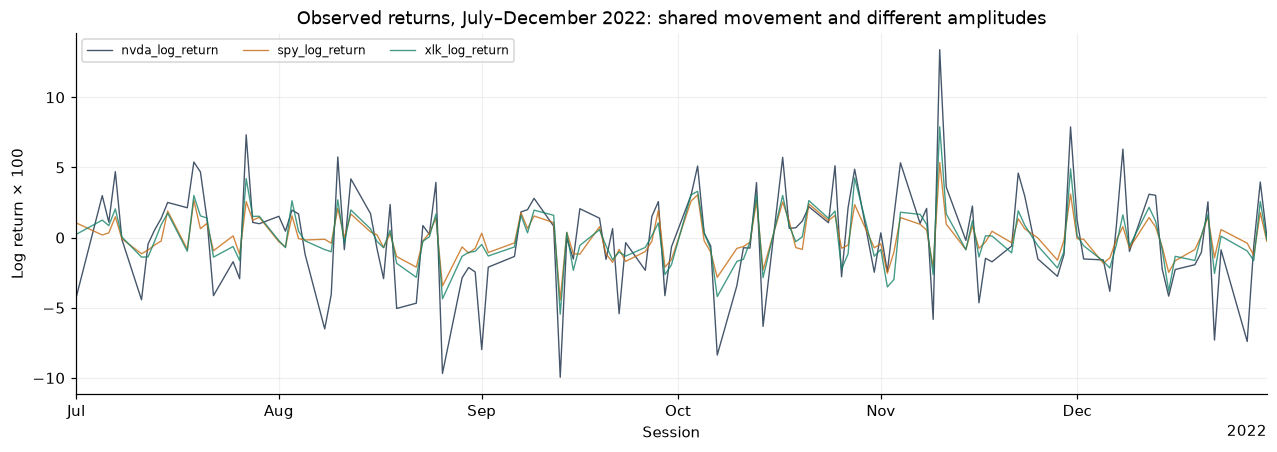

In [7]:
context_rows=[]
for ticker in ("SPY","XLK"):
    for position in (1,100):
        previous,current=series[ticker].iloc[position-1:position+1]
        manual=np.log(current/previous)
        implemented=features[f"{ticker.lower()}_log_return"].iloc[position]
        np.testing.assert_allclose(manual,implemented,rtol=0,atol=1e-15)
        context_rows.append({"ticker":ticker,"session":features.index[position],"previous Close USD":previous,
                             "current Close USD":current,"manual log return":manual,"implemented":implemented})
display(pd.DataFrame(context_rows))
training_returns=train_features[["spy_log_return","xlk_log_return"]].copy()
training_returns["nvda_log_return"]=np.log(train_raw.close/train_raw.close.shift(1))
training_returns=training_returns.dropna()
display(training_returns.corr())
lag_rows=[]
for name in ["spy_log_return","xlk_log_return"]:
    # Pair t with t+1 explicitly; both observations remain inside the training interval.
    origin_values=training_returns[name].iloc[:-1].to_numpy()
    next_values=training_returns.nvda_log_return.iloc[1:].to_numpy()
    lag_rows.append({"context":name,"same-session correlation":training_returns[name].corr(training_returns.nvda_log_return),
                     "next-session correlation":np.corrcoef(origin_values,next_values)[0,1],
                     "training pairs":len(next_values),"last target session":training_returns.index[-1]})
display(pd.DataFrame(lag_rows))
fig,ax=plt.subplots(figsize=(11.5,4),layout="constrained")
for name,color in [("nvda_log_return","#172b45"),("spy_log_return",COLORS["B"]),("xlk_log_return",COLORS["C"])]:
    part=training_returns.loc["2022-07-01":,name]
    ax.plot(part.index,part*100,label=name,color=color,lw=.9,alpha=.8)
ax.set(title="Observed returns, July–December 2022: shared movement and different amplitudes",
       ylabel="Log return × 100",xlabel="Session");ax.legend(ncol=3,fontsize=8);date_axis(ax,part.index);plt.show()

NVDA's same-session training correlations are approximately **0.655 with SPY** and **0.745 with XLK**, consistent with Notebook 01. SPY/XLK correlation is approximately **0.938**. Their correlations with next-session NVDA returns are about **−0.140 and −0.149** on the explicitly aligned training pairs. These are different questions and samples. No significance, causal relationship or future forecasting advantage follows from these coefficients. Model C's held-out comparison is the relevant evidence for the approved representation and network.

## 8. Feature construction and temporal integrity

The authoritative `calculate_features()` function carries out the causal calculations and rejects nonfinite prices or mismatched session indexes. Loading separately checks snapshot identity, financial records and session coverage; matching instruments alone would not detect a session missing from every instrument. NASDAQ is used for NVDA and NYSE is the documented regular-session proxy for SPY/XLK.

Unavailable initial values remain missing. SMA50 is the last required feature to become available, on observation 50; therefore the first **49 feature rows** are excluded for **all variants**, including A. Thirty complete input rows then produce the first target at source observation **80**. There is no backfill, centring or silent internal-row deletion. This is minimum calculability, not proof that recursive seeds have no remaining effect.

Indicator states continue across calendar years and partition boundaries. Prefix calculations and a future-value perturbation below check that earlier features and inputs remain unchanged. The perturbed values are temporary in-memory development copies for verification; source files and experiment evidence are never modified.

def calculate_features(series, config):
    """Build aligned development-only indicators without filling unavailable history."""
    closes = {}
    for ticker in ("NVDA", "SPY", "XLK"):
        s = series[ticker]
        if not isinstance(s.index, pd.DatetimeIndex) or s.index.has_duplicates or not s.index.is_monotonic_increasing:
            raise ValueError("Unique chronological session dates required")
        # Exclude 2025 before any indicator or numerical validity calculation.
        s = s.loc[config["start"]:config["validation_end"]].astype(float)
        if not np.isfinite(s).all() or (s <= 0).any():
            raise ValueError("Missing, nonfinite or nonpositive development Close")
        closes[ticker] = s
    close = closes["NVDA"]
    if any(not s.index.equals(close.index) for s in closes.values()):
        raise ValueError("Instrument sessions must match exactly")
    raw = pd.DataFrame({"close": close})
    for n in (20, 50):
        raw[f"sma{n}"] = close.rolling(n, min_periods=n).mean()
    for n in (12, 26):
        raw[f"ema{n}"] = seeded_ema(close, n)
    raw["rsi14"] = wilder_rsi(close)
    raw["macd"] = raw.ema12 - raw.ema26
    raw["signal"] = seeded_ema(raw.macd, 9)
    raw["histogram"] = raw.macd - raw.signal
    features = pd.DataFrame({"close": close})
    for name in ("sma20", "sma50", "ema12", "ema26"):
        features[f"{name}_distance"] = close / raw[name] - 1
    features["rsi14_fraction"] = raw.rsi14 / 100
    features["macd_relative"] = raw.macd / close
    features["histogram_relative"] = raw.histogram / close
    for ticker in ("SPY", "XLK"):
        # shift(1) refers only to the previous observed session, not a future quote.
        features[f"{ticker.lower()}_log_return"] = np.log(closes[ticker] / closes[ticker].shift(1))
    return raw, features

,indicator,first source observation (1-based),first valid session
0,sma20,20,2015-01-30
1,sma50,50,2015-03-16
2,ema12,12,2015-01-20
3,ema26,26,2015-02-09
4,rsi14,15,2015-01-23
5,macd,26,2015-02-09
6,signal,34,2015-02-20
7,histogram,34,2015-02-20


,model,warmup_rows,first_feature_date,first_target_date,input_unique_rows,fit_examples,validation_examples
0,A,49,2015-03-16,2015-04-28,1964,1935,502
1,B,49,2015-03-16,2015-04-28,1964,1935,502
2,C,49,2015-03-16,2015-04-28,1964,1935,502


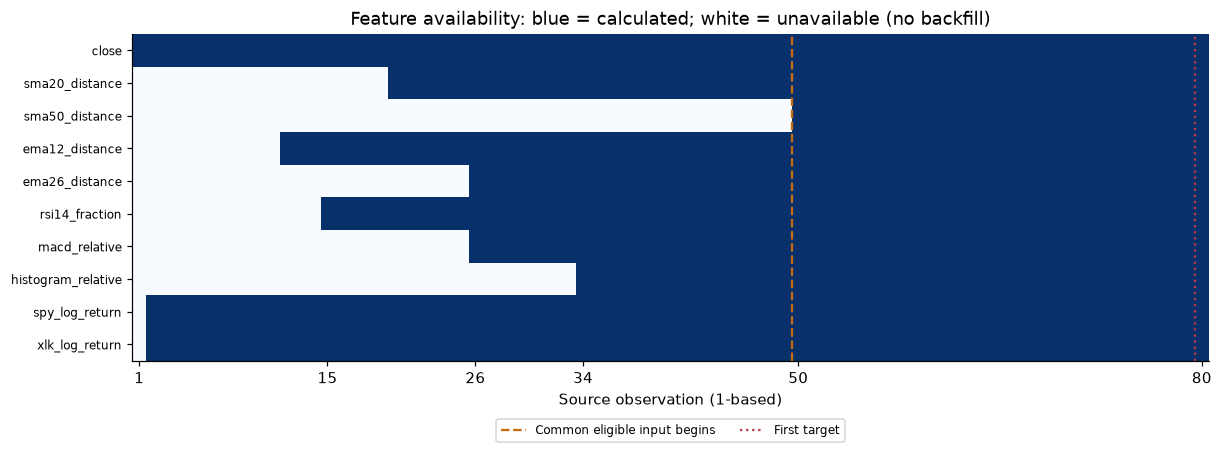

In [8]:
display(Code(inspect.getsource(calculate_features),language="python"))
first_valid=[]
expected_positions={"sma20":19,"sma50":49,"ema12":11,"ema26":25,"rsi14":14,"macd":25,"signal":33,"histogram":33}
for name,position in expected_positions.items():
    first=raw[name].first_valid_index()
    assert first==raw.index[position]
    first_valid.append({"indicator":name,"first source observation (1-based)":position+1,"first valid session":first})
display(pd.DataFrame(first_valid))
complete=np.isfinite(features[VARIANTS["C"]]).all(axis=1)
assert not complete.iloc[:49].any() and complete.iloc[49:].all()
prepared={v:prepare_feature_dataset(features,config,v) for v in VARIANTS}
reference=prepared["A"]
for variant,data in prepared.items():
    assert data.provenance==results["eligibility"][variant]
    pd.testing.assert_frame_equal(data.metadata,reference.metadata)
    np.testing.assert_array_equal(data.y,reference.y)
    np.testing.assert_array_equal(data.targets,reference.targets)
    np.testing.assert_array_equal(data.origins,reference.origins)
    assert (data.metadata.origin_date<data.metadata.target_date).all()
    positions=features.index.get_indexer(data.metadata.target_date)
    np.testing.assert_array_equal(features.index.get_indexer(data.metadata.origin_date),positions-1)
    np.testing.assert_array_equal(features.index.get_indexer(data.metadata.window_start),positions-30)
    np.testing.assert_array_equal(data.targets,series["NVDA"].reindex(data.metadata.target_date).to_numpy())
    np.testing.assert_array_equal(data.origins,series["NVDA"].reindex(data.metadata.origin_date).to_numpy())
display(pd.DataFrame([{ "model":v, **{k:d.provenance[k] for k in ["warmup_rows","first_feature_date","first_target_date", "input_unique_rows","fit_examples","validation_examples"]}} for v,d in prepared.items()]))
fig,ax=plt.subplots(figsize=(11,4),layout="constrained")
ax.imshow(np.isfinite(features[VARIANTS["C"]].iloc[:80]).T,aspect="auto",cmap="Blues",vmin=0,vmax=1,
          interpolation="nearest",extent=(-.5,79.5,9.5,-.5))
ax.set_yticks(range(10),VARIANTS["C"],fontsize=8)
ax.set_xticks([0,14,25,33,49,79],[1,15,26,34,50,80])
ax.axvline(48.5,color=COLORS["B"],ls="--",label="Common eligible input begins")
ax.axvline(78.5,color="#b83a48",ls=":",label="First target")
ax.set(title="Feature availability: blue = calculated; white = unavailable (no backfill)",xlabel="Source observation (1-based)")
ax.grid(False);ax.legend(loc="upper center",bbox_to_anchor=(.5,-.16),ncol=2,fontsize=8);plt.show()

In [9]:
# Prefix-only indicator states must agree with uninterrupted calculations.
prefix_end=config["train_end"]
prefix_series={ticker:s.loc[:prefix_end] for ticker,s in series.items()}
prefix_raw,prefix_features=calculate_features(prefix_series,dict(config,validation_end=prefix_end))
pd.testing.assert_frame_equal(prefix_raw,raw.loc[:prefix_end])
pd.testing.assert_frame_equal(prefix_features,features.loc[:prefix_end])

cutoff=pd.Timestamp("2023-06-01")
perturbed={ticker:s.copy() for ticker,s in series.items()}
for s in perturbed.values():s.loc[cutoff:]*=1.5
_,perturbed_features=calculate_features(perturbed,config)
pd.testing.assert_frame_equal(features.loc[features.index<cutoff],perturbed_features.loc[features.index<cutoff])
perturbed_data={v:prepare_feature_dataset(perturbed_features,config,v) for v in VARIANTS}
for variant,data in prepared.items():
    other=perturbed_data[variant]
    assert data.provenance==other.provenance
    earlier=(data.metadata.origin_date<cutoff).to_numpy()
    np.testing.assert_array_equal(data.X[earlier],other.X[earlier])
    np.testing.assert_array_equal(data.y[data.fit_mask],other.y[other.fit_mask])
# Saved feature tables are development-only experimental evidence, not vendor snapshots.
for filename,computed in [("indicators.json",raw),("features.json",features)]:
    saved=pd.read_json(BASE/filename,orient="table")
    assert saved.index.tolist()==computed.index.tolist() and saved.columns.tolist()==computed.columns.tolist()
    assert saved.index.max()<=pd.Timestamp(config["validation_end"])
    np.testing.assert_allclose(saved.to_numpy(),computed.to_numpy(),rtol=0,atol=1e-9,equal_nan=True)
print("Prefix continuity, future perturbation, saved feature values and all common dates verified.")

Prefix continuity, future perturbation, saved feature values and all common dates verified.


All variants have **1,935 fitting targets and 502 validation targets**. The common first feature date is **16 March 2015** and first target is **28 April 2015**. The initial training targets are 49 fewer than in Milestone 5, so reusing its earlier price-only score would confound feature effects with sample eligibility. Earlier validation closes can enter later one-step inputs once observed; scalers and fitted weights do not change.

## 9. Feature scaling and residual-target preprocessing

Each feature column has its own standardisation,
\[
z_{t,j}=\frac{x_{t,j}-\mu_j}{s_j},
\]
using a mean and population SD (ddof=0) from **1,964 unique fitting input dates**, not the flattened overlapping windows. A constant column would use scale one. Pre-normalisation reduces arbitrary price scale in derived features, while standardisation aligns their empirical training magnitudes. It does not guarantee that validation remains in the training range; values are not clipped.

The target remains a standardised dollar correction:
\[
\Delta C_{t+1}=C_{t+1}-C_t,\quad z^\Delta=(\Delta C-\mu_\Delta)/s_\Delta,\quad
\widehat C_{t+1}=C_t+s_\Delta\widehat z^\Delta+\mu_\Delta.
\]
The correction scaler uses only the **1,935 fitting labels** and is identical across variants. Its numerical values differ from Milestone 5 because the fitting sample differs, not because the formulation changed. The input scaler never substitutes for the target scaler. Zero standardised output means the fitted average correction; zero-dollar output recovers persistence.

In [10]:
fit=reference.fit_mask;evaluate=~fit
unique=features.loc[reference.provenance["first_feature_date"]:reference.provenance["last_fitting_input_date"]]
scaler_rows=[]
for variant,data in prepared.items():
    assert len(unique)==data.provenance["input_unique_rows"]
    for name,parameters in data.provenance["input_scalers"].items():
        np.testing.assert_allclose([parameters["mean"],parameters["scale"]],
                                   [unique[name].mean(),unique[name].std(ddof=0)],rtol=0,atol=1e-14)
        if variant=="C":scaler_rows.append({"feature":name,**parameters})
    corrections=data.targets-data.origins
    assert asdict(data.correction_scaler)==data.provenance["correction_scaler"]
    np.testing.assert_allclose([data.correction_scaler.mean,data.correction_scaler.scale],
                               [corrections[fit].mean(),corrections[fit].std(ddof=0)],rtol=0,atol=1e-14)
    np.testing.assert_array_equal(data.correction_scaler.transform(corrections).astype("float32"),data.y)
    # Float64 transformation/inversion verifies the dollar contract without float32 rounding.
    np.testing.assert_allclose(reconstruct_prices(data.origins,data.correction_scaler.transform(corrections),data.correction_scaler),
                               data.targets,rtol=0,atol=1e-12)
    for i in [0,np.flatnonzero(fit)[-1],np.flatnonzero(evaluate)[0],len(data.X)-1]:
        meta=data.metadata.iloc[i]
        real_window=features.loc[meta.window_start:meta.origin_date,VARIANTS[variant]]
        for j,name in enumerate(VARIANTS[variant]):
            scaler=Standardisation(**data.provenance["input_scalers"][name])
            np.testing.assert_array_equal(scaler.transform(real_window[name]).astype("float32"),data.X[i,:,j])
np.testing.assert_array_equal(prepared["A"].X[:,:,0],prepared["B"].X[:,:,0])
np.testing.assert_array_equal(prepared["B"].X,prepared["C"].X[:,:,:8])
display(pd.DataFrame(scaler_rows).set_index("feature"))
display(pd.Series(reference.provenance["correction_scaler"],name="Common correction scaler (USD)"))
print(f"Input statistics end {reference.provenance['last_fitting_input_date']}; fitting labels end {reference.provenance['last_fitting_target_date']}.")
first_validation=np.flatnonzero(evaluate)[0]
meta=reference.metadata.iloc[first_validation]
origin_features=features.loc[meta.origin_date]
display(pd.DataFrame({"unscaled at forecast origin":origin_features,
                      "standardised at forecast origin":prepared["C"].X[first_validation,-1,:]},index=VARIANTS["C"]))

,mean,scale
feature,,
close,8.161121,7.499040
sma20_distance,0.017398,0.072234
sma50_distance,0.046132,0.118571
ema12_distance,0.009075,0.046376
ema26_distance,0.021114,0.071921
rsi14_fraction,0.557907,0.128936
macd_relative,0.008705,0.034310
histogram_relative,0.000057,0.009820
spy_log_return,0.000317,0.011890


mean    0.007266
scale   0.382388
Name: Common correction scaler (USD), dtype: float64

Input statistics end 2022-12-29; fitting labels end 2022-12-30.


,unscaled at forecast origin,standardised at forecast origin
close,14.614000,0.860494
sma20_distance,-0.096021,-1.570168
sma50_distance,-0.046045,-0.777394
ema12_distance,-0.047964,-1.229912
ema26_distance,-0.066850,-1.223073
rsi14_fraction,0.410497,-1.143276
macd_relative,-0.021259,-0.873325
histogram_relative,-0.024509,-2.501495
spy_log_return,-0.002638,-0.248461
xlk_log_return,-0.001365,-0.126176


The common correction mean is **\$0.007265633** and SD **\$0.382388234**. Input statistics end on **29 December 2022**; fitting labels end on **30 December 2022**. The final fitting label is excluded from input-statistic fitting because it is not in a fitting input window. It can legitimately become the first validation origin. Recomputed scaler parameters match every recorded variant, and shared columns are identical across tensors.

## 10. Multivariate LSTM input architecture

An input tensor has dimensions **(examples, sessions, features)**. Each row of an example is one observed session; its columns are features in the recorded order. Adding features increases the width of each session's input vector, not the number of timesteps or forecast horizon:
\[
X_A:(2437,30,1),\quad X_B:(2437,30,8),\quad X_C:(2437,30,10).
\]
The following matrices show the first common fitting window. Raw feature units differ, so the tensor heatmap uses the actual standardised inputs. Within each timestep, the feature vector enters each LSTM gate's input-weight matrix; the same weights are reused over all 30 sessions. There is no separate recurrent network per indicator.

For 16 hidden units and F features,
\[
N_{\mathrm{LSTM}}=4(16)(F+16+1),\quad N_{\mathrm{Dense}}=17.
\]
Thus counts are **1,169 / 1,617 / 1,745**. Hidden state shape remains (batch,16), followed by post-LSTM Dropout(0.2) and Dense(1). Input dimensionality therefore changes capacity despite identical hidden units. The actual seed-42 checkpoints and constructor are inspected below; no weights are fitted.

**Model A: first fitting input matrix, before standardisation**

,close
2015-03-16,0.574250
2015-03-17,0.581250
2015-03-18,0.571750
2015-03-19,0.580500
2015-03-20,0.586750
2015-03-23,0.567750
2015-03-24,0.560000
2015-03-25,0.526000
2015-03-26,0.524250
2015-03-27,0.534500


**Model B: first fitting input matrix, before standardisation**

,close,sma20_distance,sma50_distance,ema12_distance,ema26_distance,rsi14_fraction,macd_relative,histogram_relative
2015-03-16,0.574250,0.022388,0.089876,0.015812,0.039255,0.634244,0.022207,-0.001674
2015-03-17,0.581250,0.032851,0.099904,0.023754,0.047893,0.663217,0.022502,-0.000873
2015-03-18,0.571750,0.014281,0.078784,0.005935,0.028423,0.594400,0.021737,-0.001621
2015-03-19,0.580500,0.027434,0.091145,0.017989,0.040757,0.632250,0.021490,-0.001213
2015-03-20,0.586750,0.035906,0.098423,0.024387,0.047929,0.656880,0.021930,-0.000425
2015-03-23,0.567750,0.001146,0.060026,-0.007443,0.012945,0.538750,0.020278,-0.002260
2015-03-24,0.560000,-0.012716,0.043161,-0.017820,-0.000817,0.499307,0.017326,-0.004419
2015-03-25,0.526000,-0.070404,-0.021404,-0.066327,-0.057188,0.370984,0.010382,-0.010215
2015-03-26,0.524250,-0.070973,-0.025847,-0.059386,-0.056107,0.365773,0.003693,-0.013578
2015-03-27,0.534500,-0.051380,-0.008312,-0.034908,-0.034960,0.417390,-0.000056,-0.013597


**Model C: first fitting input matrix, before standardisation**

,close,sma20_distance,sma50_distance,ema12_distance,ema26_distance,rsi14_fraction,macd_relative,histogram_relative,spy_log_return,xlk_log_return
2015-03-16,0.574250,0.022388,0.089876,0.015812,0.039255,0.634244,0.022207,-0.001674,0.013272,0.011741
2015-03-17,0.581250,0.032851,0.099904,0.023754,0.047893,0.663217,0.022502,-0.000873,-0.002977,0.000238
2015-03-18,0.571750,0.014281,0.078784,0.005935,0.028423,0.594400,0.021737,-0.001621,0.011950,0.013483
2015-03-19,0.580500,0.027434,0.091145,0.017989,0.040757,0.632250,0.021490,-0.001213,-0.004572,-0.002824
2015-03-20,0.586750,0.035906,0.098423,0.024387,0.047929,0.656880,0.021930,-0.000425,0.004334,0.002354
2015-03-23,0.567750,0.001146,0.060026,-0.007443,0.012945,0.538750,0.020278,-0.002260,-0.001950,0.000000
2015-03-24,0.560000,-0.012716,0.043161,-0.017820,-0.000817,0.499307,0.017326,-0.004419,-0.005635,-0.003296
2015-03-25,0.526000,-0.070404,-0.021404,-0.066327,-0.057188,0.370984,0.010382,-0.010215,-0.014762,-0.026044
2015-03-26,0.524250,-0.070973,-0.025847,-0.059386,-0.056107,0.365773,0.003693,-0.013578,-0.002384,0.000726
2015-03-27,0.534500,-0.051380,-0.008312,-0.034908,-0.034960,0.417390,-0.000056,-0.013597,0.002287,0.000725


,model,features in order,X shape,y shape
0,A,close,"(2437, 30, 1)","(2437,)"
1,B,"close, sma20_distance, sma50_distance, ema12_d...","(2437, 30, 8)","(2437,)"
2,C,"close, sma20_distance, sma50_distance, ema12_d...","(2437, 30, 10)","(2437,)"


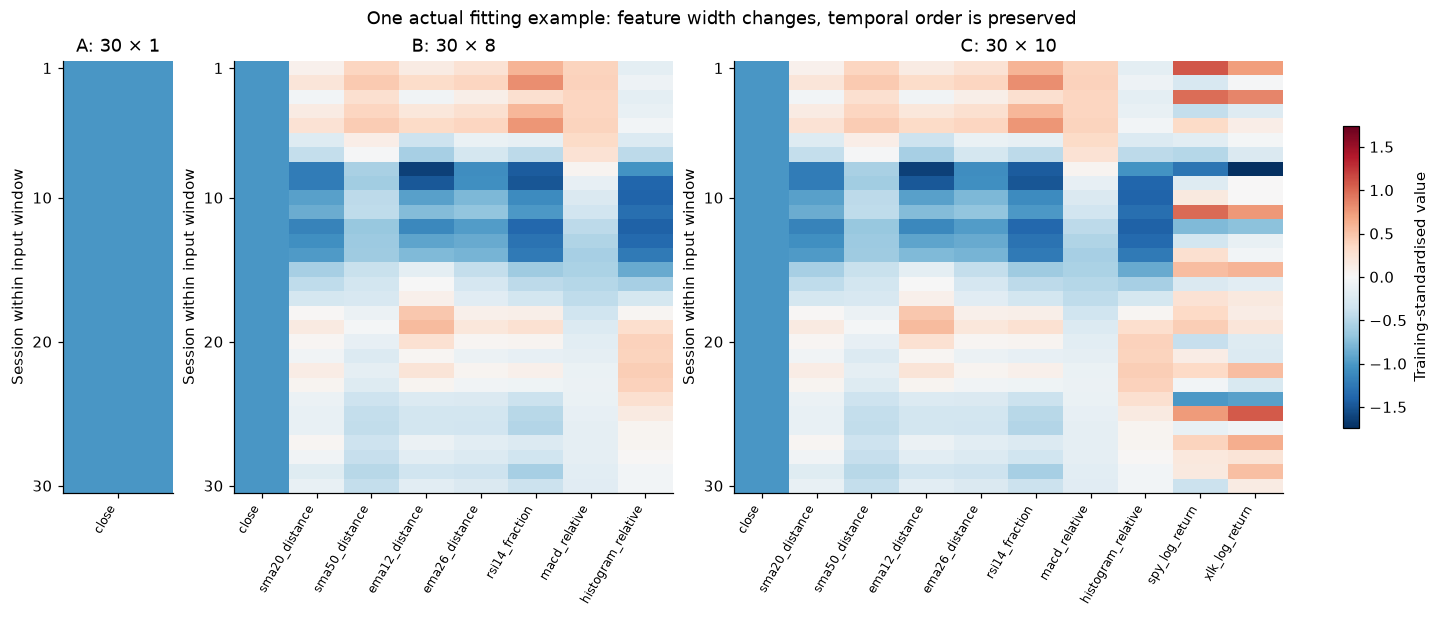

Model A: feature order ['close']


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,169 (4.57 KB)

 Trainable params: 1,169 (4.57 KB)

...

 Total params: 1,745 (6.82 KB)

 Trainable params: 1,745 (6.82 KB)

 Non-trainable params: 0 (0.00 B)

,layer,input,output,parameters
0,LSTM,"(None, 30, 10)","(None, 16)",1728
1,Dropout,"(None, 16)","(None, 16)",0
2,Dense,"(None, 16)","(None, 1)",17


def build_model(settings, seed, lookback=30, features=1):
    """Initialise an independent LSTM that predicts a standardised correction."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(lookback, features)),
        tf.keras.layers.LSTM(settings["units"], stateful=False),
        tf.keras.layers.Dropout(settings["dropout"], seed=seed),
        tf.keras.layers.Dense(1),
    ])
    # MSE is in correction-standardised units; evaluation reconstructs USD prices.
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=settings["learning_rate"]),
                  loss="mean_squared_error")
    return model

In [11]:
shape_rows=[]
for variant,data in prepared.items():
    assert data.X.shape==(len(reference.targets),30,len(VARIANTS[variant]))
    shape_rows.append({"model":variant,"features in order":", ".join(VARIANTS[variant]),
                       "X shape":data.X.shape,"y shape":data.y.shape})
    example=data.metadata.iloc[0]
    display(Markdown(f"**Model {variant}: first fitting input matrix, before standardisation**"))
    with pd.option_context("display.max_rows",35,"display.max_columns",12):
        display(features.loc[example.window_start:example.origin_date,VARIANTS[variant]])
display(pd.DataFrame(shape_rows))
fig,axes=plt.subplots(1,3,figsize=(13,5.5),layout="constrained",gridspec_kw={"width_ratios":[1,4,5]})
limit=max(float(np.max(np.abs(d.X[0]))) for d in prepared.values())
for ax,(variant,data) in zip(axes,prepared.items()):
    image=ax.imshow(data.X[0],aspect="auto",cmap="RdBu_r",vmin=-limit,vmax=limit)
    ax.grid(False);ax.set_xticks(range(len(VARIANTS[variant])),VARIANTS[variant],rotation=60,ha="right",fontsize=8)
    ax.set_yticks([0,9,19,29],[1,10,20,30]);ax.set(title=f"{variant}: 30 × {len(VARIANTS[variant])}",ylabel="Session within input window")
fig.colorbar(image,ax=axes,label="Training-standardised value",shrink=.7)
fig.suptitle("One actual fitting example: feature width changes, temporal order is preserved")
plt.show()
models={}
for variant in VARIANTS:
    checkpoint=tf.keras.models.load_model(BASE/f"{variant}_seed_42/model.keras",compile=False)
    models[(variant,42)]=checkpoint
    print(f"Model {variant}: feature order {VARIANTS[variant]}")
    checkpoint.summary()
    assert checkpoint.input_shape==(None,30,len(VARIANTS[variant])) and checkpoint.output_shape==(None,1)
    assert checkpoint.count_params()==4*16*(len(VARIANTS[variant])+16+1)+17
    assert tuple(checkpoint.layers[0].cell.kernel.shape)==(len(VARIANTS[variant]),64)
    assert tuple(checkpoint.layers[0].cell.recurrent_kernel.shape)==(16,64)
    assert checkpoint.layers[0].units==16 and checkpoint.layers[1].rate==.2
    assert not checkpoint.layers[0].stateful and not checkpoint.layers[0].return_sequences
    assert not checkpoint.layers[1].trainable_weights
    display(pd.DataFrame([{ "layer":layer.__class__.__name__,"input":str(layer.input.shape),
                           "output":str(layer.output.shape),"parameters":layer.count_params()} for layer in checkpoint.layers]))
display(Code(inspect.getsource(build_model),language="python"))

## 11. Controlled experimental design

The approved budget is **3 feature sets × 3 paired seeds = 9 fits**. All use 16 units, dropout 0.2, Adam learning rate 0.001, batch size 32, 30 sessions, **19 fixed epochs**, and standardised dollar-correction MSE. Each model/seed receives fresh weights. No internal hyperparameter search is repeated and no validation loss is passed to training. Every saved model retains its epoch-19 weights, even if training loss was lower earlier.

Identical fitting examples, target dates, labels and shared-feature scalers make the comparisons interpretable. Paired seeds **42,123,2026** control seed identifiers but do not produce identical weight arrays or random paths across different input shapes. Three repetitions quantify a small sample of variability; they do not establish statistical significance.

Milestone 5 used 1,984 fitting examples; this comparison uses **1,935**. The new A control is necessary. Baselines retain their recorded fitting conventions: persistence has no fitted parameters, and ARIMA uses the full historical fitting series. They are score comparators on identical validation dates, not models with identical training representations. Fixed units, epochs and sequence lengths also do not isolate feature information from increased parameter counts or the longer effective history of indicators.

,experiment,fitting examples,unique fitting inputs,first fitting target
0,Milestone 5 price-only,1984,2013,2015-02-17
1,Milestone 6 Model A,1935,1964,2015-04-28


,model,seed,training MSE epoch 1,training MSE epoch 19,lowest training MSE epoch,retained epoch,updates
0,A,42,1.007707,0.996310,18,19,1159
1,A,123,0.997111,0.995785,15,19,1159
2,A,2026,1.000432,0.996509,19,19,1159
3,B,42,1.019647,0.967719,19,19,1159
4,B,123,1.007530,0.960375,19,19,1159
5,B,2026,1.001962,0.971020,19,19,1159
6,C,42,1.016655,0.941967,19,19,1159
7,C,123,1.010447,0.943348,18,19,1159
8,C,2026,0.995296,0.945154,19,19,1159


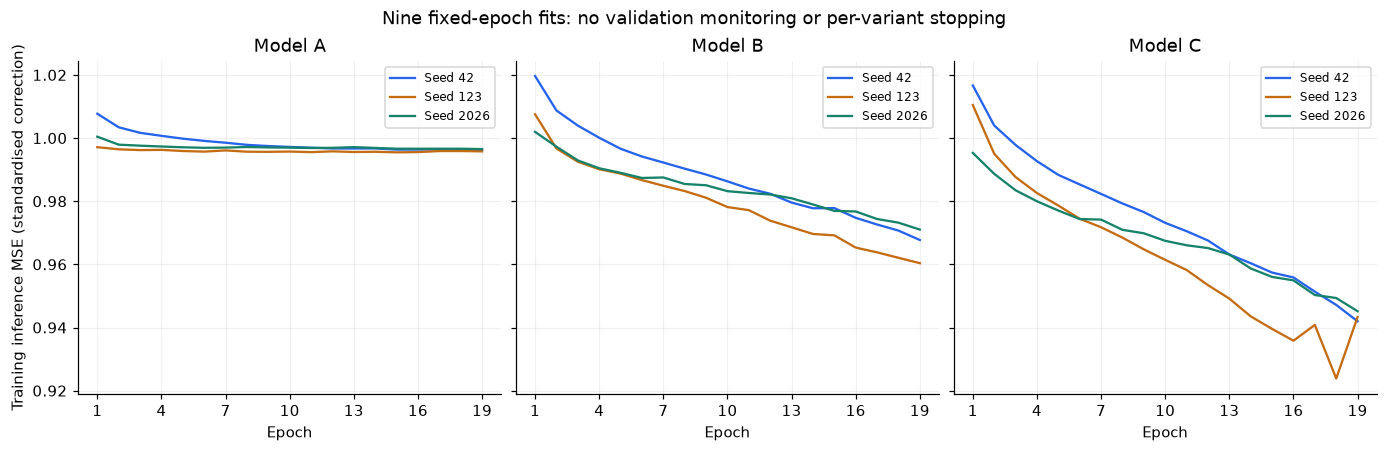

In [12]:
for key in ["units","dropout","learning_rate","batch_size"]:
    assert protocol[key]==selected["configuration"][key]
assert protocol["epochs"]==selected["epochs"]==19
assert protocol["lookback"]==selected["lookback"]==30 and protocol["seeds"]==selected["seeds"]
assert not protocol["early_stopping"]
assert {(r["variant"],r["seed"]) for r in runs}=={(v,s) for v in VARIANTS for s in SEEDS}
old_summary=json.loads((ROOT/"artifacts/lstm_v1/final/C_seed_42/summary.json").read_text())
display(pd.DataFrame([{"experiment":"Milestone 5 price-only","fitting examples":old_summary["scaling"]["fit_examples"],
                       "unique fitting inputs":old_summary["scaling"]["input_unique_rows"],"first fitting target":old_summary["scaling"]["target_first_date"]},
                      {"experiment":"Milestone 6 Model A","fitting examples":reference.provenance["fit_examples"],
                       "unique fitting inputs":reference.provenance["input_unique_rows"],"first fitting target":reference.provenance["first_target_date"]}]))
histories={};history_rows=[]
updates_per_epoch=math.ceil(int(fit.sum())/protocol["batch_size"])
assert updates_per_epoch==61 and updates_per_epoch*19==1159
for run in runs:
    key=(run["variant"],run["seed"]);folder=BASE/f"{key[0]}_seed_{key[1]}"
    assert json.loads((folder/"summary.json").read_text())==run
    assert run["settings"]==protocol and run["scaling"]==prepared[key[0]].provenance
    assert run["epochs_completed"]==19 and run["best_epoch"] is None and not run["stopped_early"]
    history=pd.DataFrame(json.loads((folder/"history.json").read_text()))
    assert history.epoch.tolist()==list(range(1,20)) and "validation_mse" not in history
    np.testing.assert_array_equal(history.optimizer_steps,history.epoch*updates_per_epoch)
    assert run["optimizer_steps"]==1159
    histories[key]=history
    history_rows.append({"model":key[0],"seed":key[1],"training MSE epoch 1":history.training_inference_mse.iloc[0],
                         "training MSE epoch 19":history.training_inference_mse.iloc[-1],
                         "lowest training MSE epoch":int(history.loc[history.training_inference_mse.idxmin(),"epoch"]),
                         "retained epoch":run["epochs_completed"],"updates":run["optimizer_steps"]})
display(pd.DataFrame(history_rows))
fig,axes=plt.subplots(1,3,figsize=(12.5,4),layout="constrained",sharey=True)
for ax,variant in zip(axes,VARIANTS):
    for seed in SEEDS:
        h=histories[(variant,seed)]
        ax.plot(h.epoch,h.training_inference_mse,color=SEED_COLORS[seed],label=f"Seed {seed}")
    ax.set(title=f"Model {variant}",xlabel="Epoch",xticks=[1,4,7,10,13,16,19]);ax.legend(fontsize=8)
axes[0].set_ylabel("Training inference MSE (standardised correction)")
fig.suptitle("Nine fixed-epoch fits: no validation monitoring or per-variant stopping")
plt.show()

Every run records **1,159 updates** (61 batches × 19 epochs; the last batch contains 15 examples). End-of-epoch inference loss disables dropout and uses fixed weights, unlike online minibatch loss. B and C achieve lower training inference MSE than A, but this is fitting evidence only. For example, C/seed123 has a lower training loss at epoch 18 than 19; retaining epoch 19 follows the predefined protocol. There is no validation-by-epoch history from which to locate an optimal external stopping point.

## 12. Actual multivariate forecasting demonstration

The demonstration uses **seed 42** for all models and the **first validation target: 3 January 2023**, chosen by date rather than forecasting accuracy. The input ends at **30 December 2022**. Each feature matrix uses the same 30 session dates. We display its raw and scaled values, call the loaded model in inference mode, invert the correction scaler and add the unscaled origin Close. Only then is the target revealed for scoring.

The `prepare_feature_dataset()` tensor is the forecasting input. Applying each saved `Standardisation` object to this one displayed window is a verification of that tensor, not a second production preprocessing pipeline. Earlier prefix/perturbation checks show that later observations cannot alter these inputs. All weights and scalers remain fixed during subsequent rolling one-step forecasts.

**Model A: 2022-12-30 origin → 2023-01-03 target**

,close
2022-11-17,15.677000
2022-11-18,15.409000
2022-11-21,15.317000
2022-11-22,16.038000
2022-11-23,16.518999
2022-11-25,16.270000
2022-11-28,15.827000
2022-11-29,15.639000
2022-11-30,16.923000
2022-12-01,17.135000


,z(close)
2022-11-17,1.002245
2022-11-18,0.966508
2022-11-21,0.954239
2022-11-22,1.050385
2022-11-23,1.114526
2022-11-25,1.081322
2022-11-28,1.022248
2022-11-29,0.997178
2022-11-30,1.168400
2022-12-01,1.196670


**Model B: 2022-12-30 origin → 2023-01-03 target**

,close,sma20_distance,sma50_distance,ema12_distance,ema26_distance,rsi14_fraction,macd_relative,histogram_relative
2022-11-17,15.677000,0.098706,0.181531,0.033151,0.094024,0.615249,0.053856,0.015206
2022-11-18,15.409000,0.068900,0.159546,0.013075,0.069355,0.588849,0.051950,0.010103
2022-11-21,15.317000,0.052595,0.151216,0.005939,0.058035,0.579654,0.048948,0.005479
2022-11-22,16.038000,0.091726,0.200162,0.044725,0.099059,0.628601,0.047320,0.004645
2022-11-23,16.518999,0.110771,0.229914,0.063612,0.121058,0.657273,0.048178,0.005396
2022-11-25,16.270000,0.082765,0.205378,0.039967,0.095706,0.630152,0.048915,0.004383
2022-11-28,15.827000,0.046344,0.168008,0.009841,0.060697,0.583983,0.047478,0.001359
2022-11-29,15.639000,0.026646,0.150302,-0.001823,0.044376,0.565063,0.044318,-0.001884
2022-11-30,16.923000,0.098746,0.237921,0.066976,0.119333,0.648763,0.043839,0.000914
2022-12-01,17.135000,0.098545,0.246365,0.067152,0.122270,0.660384,0.046022,0.002903


,z(close),z(sma20_distance),z(sma50_distance),z(ema12_distance),z(ema26_distance),z(rsi14_fraction),z(macd_relative),z(histogram_relative)
2022-11-17,1.002245,1.125630,1.141919,0.519156,1.013742,0.444730,1.315940,1.542641
2022-11-18,0.966508,0.712997,0.956506,0.086263,0.670745,0.239981,1.260411,1.022986
2022-11-21,0.954239,0.487272,0.886253,-0.067610,0.513353,0.168667,1.172897,0.552148
2022-11-22,1.050385,1.028994,1.299046,0.768729,1.083760,0.548285,1.125471,0.467193
2022-11-23,1.114526,1.292655,1.549969,1.175986,1.389636,0.770658,1.150461,0.543672
2022-11-25,1.081322,0.904934,1.343040,0.666135,1.037135,0.560317,1.171945,0.440491
2022-11-28,1.022248,0.400728,1.027871,0.016525,0.550357,0.202244,1.130067,0.132638
2022-11-29,0.997178,0.128027,0.878543,-0.234995,0.323438,0.055500,1.037947,-0.197691
2022-11-30,1.168400,1.126184,1.617499,1.248516,1.365650,0.704661,1.024006,0.087291
2022-12-01,1.196670,1.123402,1.688712,1.252310,1.406476,0.794791,1.087628,0.289764


**Model C: 2022-12-30 origin → 2023-01-03 target**

,close,sma20_distance,sma50_distance,ema12_distance,ema26_distance,rsi14_fraction,macd_relative,histogram_relative,spy_log_return,xlk_log_return
2022-11-17,15.677000,0.098706,0.181531,0.033151,0.094024,0.615249,0.053856,0.015206,-0.003065,0.001289
2022-11-18,15.409000,0.068900,0.159546,0.013075,0.069355,0.588849,0.051950,0.010103,0.004530,0.001136
2022-11-21,15.317000,0.052595,0.151216,0.005939,0.058035,0.579654,0.048948,0.005479,-0.003643,-0.010808
2022-11-22,16.038000,0.091726,0.200162,0.044725,0.099059,0.628601,0.047320,0.004645,0.013367,0.019177
2022-11-23,16.518999,0.110771,0.229914,0.063612,0.121058,0.657273,0.048178,0.005396,0.006282,0.008820
2022-11-25,16.270000,0.082765,0.205378,0.039967,0.095706,0.630152,0.048915,0.004383,-0.000224,-0.005821
2022-11-28,15.827000,0.046344,0.168008,0.009841,0.060697,0.583983,0.047478,0.001359,-0.016086,-0.021640
2022-11-29,15.639000,0.026646,0.150302,-0.001823,0.044376,0.565063,0.044318,-0.001884,-0.001719,-0.009839
2022-11-30,16.923000,0.098746,0.237921,0.066976,0.119333,0.648763,0.043839,0.000914,0.031015,0.048989
2022-12-01,17.135000,0.098545,0.246365,0.067152,0.122270,0.660384,0.046022,0.002903,-0.000736,0.001396


,z(close),z(sma20_distance),z(sma50_distance),z(ema12_distance),z(ema26_distance),z(rsi14_fraction),z(macd_relative),z(histogram_relative),z(spy_log_return),z(xlk_log_return)
2022-11-17,1.002245,1.125630,1.141919,0.519156,1.013742,0.444730,1.315940,1.542641,-0.284372,0.047802
2022-11-18,0.966508,0.712997,0.956506,0.086263,0.670745,0.239981,1.260411,1.022986,0.354347,0.037768
2022-11-21,0.954239,0.487272,0.886253,-0.067610,0.513353,0.168667,1.172897,0.552148,-0.332996,-0.745104
2022-11-22,1.050385,1.028994,1.299046,0.768729,1.083760,0.548285,1.125471,0.467193,1.097557,1.220174
2022-11-23,1.114526,1.292655,1.549969,1.175986,1.389636,0.770658,1.150461,0.543672,0.501669,0.541372
2022-11-25,1.081322,0.904934,1.343040,0.666135,1.037135,0.560317,1.171945,0.440491,-0.045457,-0.418241
2022-11-28,1.022248,0.400728,1.027871,0.016525,0.550357,0.202244,1.130067,0.132638,-1.379461,-1.455001
2022-11-29,0.997178,0.128027,0.878543,-0.234995,0.323438,0.055500,1.037947,-0.197691,-0.171212,-0.681543
2022-11-30,1.168400,1.126184,1.617499,1.248516,1.365650,0.704661,1.024006,0.087291,2.581717,3.174111
2022-12-01,1.196670,1.123402,1.688712,1.252310,1.406476,0.794791,1.087628,0.289764,-0.088548,0.054823


,model,input shape,origin Close USD,predicted standardised correction,predicted correction USD,forecast USD,actual USD,signed error USD,absolute error USD
0,A,"(1, 30, 1)",14.614000,0.043057,0.023730,14.637731,14.315000,0.322731,0.322731
1,B,"(1, 30, 8)",14.614000,-0.235035,-0.082609,14.531391,14.315000,0.216392,0.216392
2,C,"(1, 30, 10)",14.614000,-0.256076,-0.090655,14.523346,14.315000,0.208346,0.208346


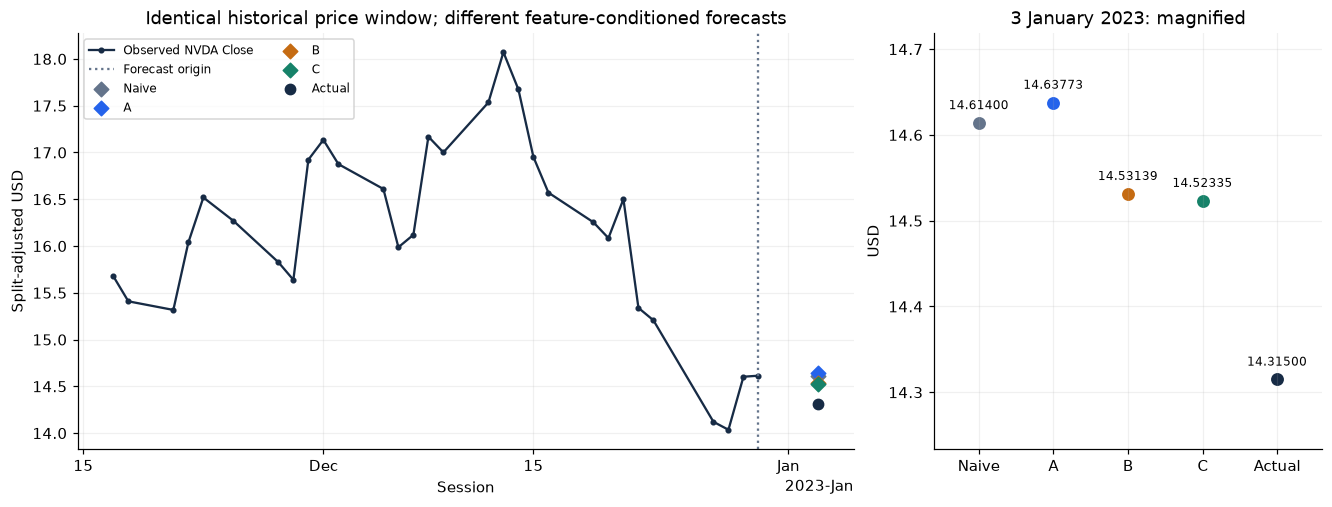

In [13]:
def read_predictions(path):
    """Read a saved development forecast table and verify its temporal bounds."""
    table=pd.read_json(path)
    for column in ["origin_date","target_date"]:table[column]=pd.to_datetime(table[column])
    assert table.target_date.is_unique and table.target_date.is_monotonic_increasing
    assert (table.origin_date<table.target_date).all() and table.target_date.max()<=pd.Timestamp(config["validation_end"])
    return table

# Rebuilding the feature prefix uses only information available at this forecast origin.
origin_end=str(meta.origin_date.date())
_,origin_prefix=calculate_features({t:s.loc[:origin_end] for t,s in series.items()},dict(config,validation_end=origin_end))
pd.testing.assert_frame_equal(origin_prefix.loc[meta.window_start:meta.origin_date],features.loc[meta.window_start:meta.origin_date])
demo_rows=[];demo_predictions={};saved_tables={}
for variant,data in prepared.items():
    names=data.provenance["feature_names"]
    matrix=features.loc[meta.window_start:meta.origin_date,names]
    scaled=pd.DataFrame({name:Standardisation(**data.provenance["input_scalers"][name]).transform(matrix[name]) for name in names},index=matrix.index)
    np.testing.assert_array_equal(scaled.to_numpy().astype("float32"),data.X[first_validation])
    display(Markdown(f"**Model {variant}: {meta.origin_date.date()} origin → {meta.target_date.date()} target**"))
    with pd.option_context("display.max_rows",35,"display.max_columns",12):
        display(matrix);display(scaled.rename(columns=lambda name:f"z({name})"))
    X=data.X[first_validation:first_validation+1]
    model=models[(variant,42)]
    standardised=predict_standardised(model,X)
    scaler=Standardisation(**data.provenance["correction_scaler"])
    correction=scaler.inverse_transform(standardised)
    prediction=reconstruct_prices(data.origins[first_validation:first_validation+1],standardised,scaler)
    actual=float(data.targets[first_validation])  # Scoring observation, not a model input.
    saved=read_predictions(BASE/f"{variant}_seed_42/predictions.json")
    saved_tables[(variant,42)]=saved
    assert saved.target_date.iloc[0]==meta.target_date
    np.testing.assert_allclose(prediction[0],saved.prediction.iloc[0],rtol=0,atol=1e-7)
    altered_prediction=predict_standardised(model,perturbed_data[variant].X[first_validation:first_validation+1])
    np.testing.assert_array_equal(standardised,altered_prediction)
    demo_predictions[variant]=float(prediction[0])
    demo_rows.append({"model":variant,"input shape":X.shape,"origin Close USD":data.origins[first_validation],
                      "predicted standardised correction":standardised[0],"predicted correction USD":correction[0],
                      "forecast USD":prediction[0],"actual USD":actual,"signed error USD":prediction[0]-actual,
                      "absolute error USD":abs(prediction[0]-actual)})
display(pd.DataFrame(demo_rows))
window=series["NVDA"].loc[meta.window_start:meta.origin_date]
naive_demo=float(window.iloc[-1])
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained",gridspec_kw={"width_ratios":[2,1]})
axes[0].plot(window.index,window,color="#172b45",marker=".",label="Observed NVDA Close")
axes[0].axvline(meta.origin_date,color="#64748b",ls=":",label="Forecast origin")
points={"Naive":naive_demo,**demo_predictions,"Actual":actual}
point_colors={"Naive":"#64748b",**COLORS,"Actual":"#172b45"}
for name,value in points.items():axes[0].scatter(meta.target_date,value,color=point_colors[name],marker="o" if name=="Actual" else "D",s=45,label=name,zorder=4)
axes[0].set(title="Identical historical price window; different feature-conditioned forecasts",ylabel="Split-adjusted USD",xlabel="Session")
axes[0].legend(ncol=2,fontsize=8);date_axis(axes[0])
for i,(name,value) in enumerate(points.items()):
    axes[1].scatter(i,value,color=point_colors[name],s=55)
    axes[1].annotate(f"{value:.5f}",(i,value),xytext=(0,9),textcoords="offset points",ha="center",fontsize=8)
axes[1].set(xticks=range(len(points)),xticklabels=list(points),ylabel="USD",title="3 January 2023: magnified")
axes[1].margins(x=.15,y=.25);plt.show()

The same origin price is carried into each forecast, while the learned corrections differ because each feature set and input-weight matrix is fitted separately. This example verifies the computational path and saved predictions; it cannot rank models over the full period. A negative correction is not a negative predicted price. The known origin, not the future target, is used in reconstruction.

### Verify all nine checkpoints

The loop below reproduces all 502 forecasts per run using the authoritative functions, checks feature order and scalers, inspects actual model/optimiser configuration, and recalculates both validation metrics and final-epoch training inference MSE. Loading with `compile=False` performs inference without optimiser updates. JSON forecasts were saved to ten decimal places; prediction tolerance is \$0.000001 and metric tolerance is \$0.0000001. Observed discrepancies are reported explicitly. This is saved-checkpoint reproduction, not an independently repeated training experiment.

In [14]:
verification_rows=[];predictions={};measured_runs=[]
for run in runs:
    variant,seed=run["variant"],run["seed"];key=(variant,seed)
    data=prepared[variant];folder=BASE/f"{variant}_seed_{seed}"
    saved=read_predictions(folder/"predictions.json");saved_tables[key]=saved
    for column in ["origin_date","target_date"]:
        assert saved[column].tolist()==data.metadata.loc[evaluate,column].tolist()
    np.testing.assert_allclose(saved.actual_close,data.targets[evaluate],rtol=0,atol=1e-9)
    np.testing.assert_allclose(saved.origin_close,data.origins[evaluate],rtol=0,atol=1e-9)
    assert run["scaling"]==data.provenance and run["settings"]==protocol
    model=models[key] if key in models else tf.keras.models.load_model(folder/"model.keras",compile=False)
    models[key]=model
    assert model.input_shape==(None,30,len(VARIANTS[variant])) and model.output_shape==(None,1)
    assert model.count_params()==run["trainable_parameters"]==4*16*(len(VARIANTS[variant])+17)+17
    recurrent,dropout,dense=model.layers
    assert recurrent.units==16 and not recurrent.stateful and not recurrent.return_sequences
    assert recurrent.dropout==0 and recurrent.recurrent_dropout==0 and dropout.rate==.2
    assert dense.units==1 and dense.get_config()["activation"]=="linear"
    with zipfile.ZipFile(folder/"model.keras") as archive:
        checkpoint_config=json.loads(archive.read("config.json"))
    compile_config=checkpoint_config["compile_config"]
    assert compile_config["optimizer"]["class_name"]=="Adam"
    assert compile_config["loss"]=="mean_squared_error"
    np.testing.assert_allclose(compile_config["optimizer"]["config"]["learning_rate"],protocol["learning_rate"],rtol=1e-6)
    z=predict_standardised(model,data.X[evaluate])
    forecast=reconstruct_prices(data.origins[evaluate],z,data.correction_scaler)
    np.testing.assert_allclose(forecast,saved.prediction,rtol=0,atol=1e-6)
    np.testing.assert_allclose(data.correction_scaler.inverse_transform(z),saved.predicted_correction,rtol=0,atol=1e-6)
    metrics=error_metrics(data.targets[evaluate],forecast)
    for metric in ["mae_usd","rmse_usd"]:np.testing.assert_allclose(metrics[metric],run["evaluation_metrics"][metric],rtol=0,atol=1e-7)
    train_z=predict_standardised(model,data.X[fit])
    train_mse=float(np.mean((train_z-data.y[fit])**2))
    np.testing.assert_allclose(train_mse,histories[key].training_inference_mse.iloc[-1],rtol=1e-6,atol=1e-8)
    predictions[key]=forecast
    measured_runs.append({"variant":variant,"seed":seed,**metrics})
    verification_rows.append({"model":variant,"seed":seed,"target dates":len(saved),"parameters":model.count_params(),
                              "max prediction discrepancy USD":float(np.max(np.abs(forecast-saved.prediction))),
                              "reproduced epoch-19 training MSE":train_mse})
verification=pd.DataFrame(verification_rows)
display(verification)
print("Maximum checkpoint/JSON discrepancy USD:",verification["max prediction discrepancy USD"].max())

,model,seed,target dates,parameters,max prediction discrepancy USD,reproduced epoch-19 training MSE
0,A,42,502,1169,0.000000,0.996310
1,A,123,502,1169,0.000000,0.995785
2,A,2026,502,1169,0.000000,0.996509
3,B,42,502,1617,0.000000,0.967719
4,B,123,502,1617,0.000000,0.960375
5,B,2026,502,1617,0.000000,0.971020
6,C,42,502,1745,0.000000,0.941967
7,C,123,502,1745,0.000000,0.943348
8,C,2026,502,1745,0.000000,0.945154


Maximum checkpoint/JSON discrepancy USD: 4.999911595859885e-11


## 13. Experimental results and grouped feature comparisons

All errors below use the same target dates and original USD price scale:
\[
MAE=\frac1n\sum_i|\widehat C_i-C_i|,\quad RMSE=\sqrt{\frac1n\sum_i(\widehat C_i-C_i)^2}.
\]
RMSE puts more weight on large misses. Aggregate results are **means of individual run metrics**, with sample SD (ddof=1); they are not an averaged-prediction ensemble or confidence intervals. Baseline dates, origins and actual prices are checked before comparison. The existing reporting module's `aggregate()` function computes the same summaries without invoking its report-writing entry point.

Paired contrasts are
\[
\Delta MAE_{B-A}=MAE_B-MAE_A,\qquad\Delta MAE_{C-B}=MAE_C-MAE_B.
\]
Negative means the added group reduces that seed's error; positive means it increases error. B−A examines the entire technical bundle. C−B examines context **conditional on** that bundle; there is no price-plus-context-only variant, and no single-indicator ablation.

,variant,seed,n,mae_usd,rmse_usd
0,A,42,502,1.692171,2.589636
1,A,123,502,1.716511,2.612893
2,A,2026,502,1.699118,2.596612
3,B,42,502,1.708604,2.601668
4,B,123,502,1.714596,2.609530
5,B,2026,502,1.728711,2.618529
6,C,42,502,1.716668,2.607559
7,C,123,502,1.703816,2.596601
8,C,2026,502,1.725431,2.614373


,model,MAE mean USD,MAE seed SD,RMSE mean USD,RMSE seed SD
0,naive,1.689494,NaN,2.589324,NaN
1,arima,1.720201,NaN,2.612846,NaN
2,A,1.702600,0.012538,2.599713,0.011935
3,B,1.717304,0.010324,2.609909,0.008437
4,C,1.715305,0.010872,2.606177,0.008966


,seed,B_minus_A_mae_usd,C_minus_B_mae_usd,B_minus_A_rmse_usd,C_minus_B_rmse_usd
0,42,0.016433,0.008064,0.012033,0.005890
1,123,-0.001916,-0.010780,-0.003362,-0.012930
2,2026,0.029593,-0.003281,0.021917,-0.004156


Mean paired differences (USD):


B_minus_A_mae_usd     0.014704
C_minus_B_mae_usd    -0.001999
B_minus_A_rmse_usd    0.010196
C_minus_B_rmse_usd   -0.003732
dtype: float64

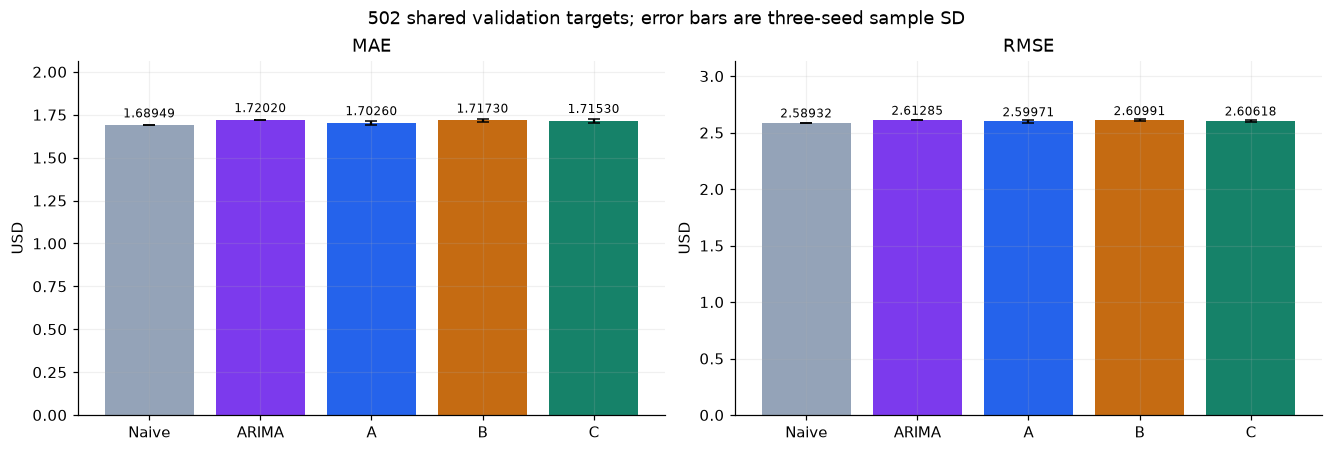

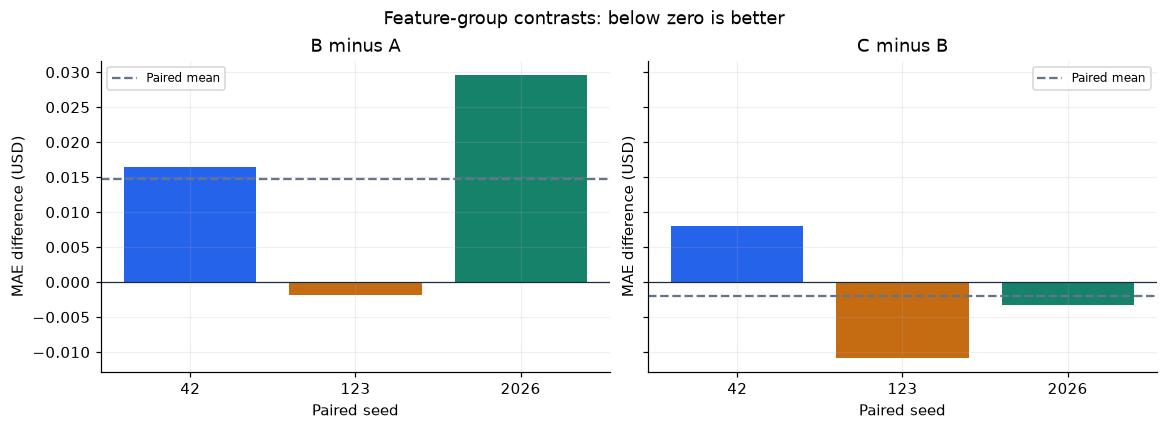

In [15]:
# The reporting module defines aggregate(); its main() is not invoked.
# Restore the inline backend after importing its script-level plotting backend setting.
backend_before=plt.get_backend()
report_module=runpy.run_path(str(ROOT/"scripts/report_feature_experiments.py"))
plt.switch_backend(backend_before)
aggregate=report_module["aggregate"]
truth=reference.targets[evaluate]
dates=reference.metadata.loc[evaluate,"target_date"].reset_index(drop=True)
naive=reference.origins[evaluate]
naive_saved=read_predictions(ROOT/"artifacts/naive_v1/validation_predictions.json")
arima_saved=read_predictions(ROOT/"artifacts/arima_v1/validation_predictions.json")
for saved in [naive_saved,arima_saved]:
    for column in ["target_date","origin_date"]:
        assert saved[column].tolist()==reference.metadata.loc[evaluate,column].tolist()
    np.testing.assert_allclose(saved.actual_close,truth,rtol=0,atol=1e-9)
np.testing.assert_allclose(naive,naive_saved.prediction,rtol=0,atol=1e-9)
baselines={"naive":error_metrics(truth,naive),"arima":error_metrics(truth,arima_saved.arima_prediction)}
for name in baselines:
    for metric in ["mae_usd","rmse_usd"]:
        np.testing.assert_allclose(baselines[name][metric],results["baselines"][name][metric],rtol=0,atol=1e-7)
run_metrics=pd.DataFrame(measured_runs)
display(run_metrics)
grouped={v:aggregate([r for r in measured_runs if r["variant"]==v]) for v in VARIANTS}
for variant,values in grouped.items():
    for metric in ["mae_usd","rmse_usd"]:
        for statistic in ["mean","std"]:
            np.testing.assert_allclose(values[metric][statistic],results["aggregate"][variant][metric][statistic],rtol=0,atol=1e-7)
summary_rows=[{"model":name,"MAE mean USD":m["mae_usd"],"MAE seed SD":np.nan,
               "RMSE mean USD":m["rmse_usd"],"RMSE seed SD":np.nan} for name,m in baselines.items()]
summary_rows += [{"model":v,"MAE mean USD":g["mae_usd"]["mean"],"MAE seed SD":g["mae_usd"]["std"],
                  "RMSE mean USD":g["rmse_usd"]["mean"],"RMSE seed SD":g["rmse_usd"]["std"]} for v,g in grouped.items()]
display(pd.DataFrame(summary_rows))
assert (run_metrics.mae_usd>baselines["naive"]["mae_usd"]).all()
assert (run_metrics.rmse_usd>baselines["naive"]["rmse_usd"]).all()
paired_rows=[]
for seed in SEEDS:
    entries=run_metrics.loc[run_metrics.seed.eq(seed)].set_index("variant")
    row={"seed":seed}
    for metric in ["mae_usd","rmse_usd"]:
        row[f"B_minus_A_{metric}"]=entries.loc["B",metric]-entries.loc["A",metric]
        row[f"C_minus_B_{metric}"]=entries.loc["C",metric]-entries.loc["B",metric]
    paired_rows.append(row)
paired=pd.DataFrame(paired_rows)
np.testing.assert_allclose(paired.to_numpy(),pd.DataFrame(results["paired_differences"])[paired.columns].to_numpy(),rtol=0,atol=1e-7)
display(paired)
print("Mean paired differences (USD):");display(paired.drop(columns="seed").mean())
fig,axes=plt.subplots(1,2,figsize=(12,4),layout="constrained")
for ax,metric,title in zip(axes,["mae_usd","rmse_usd"],["MAE","RMSE"]):
    values=[baselines[name][metric] for name in ("naive","arima")]+[grouped[v][metric]["mean"] for v in VARIANTS]
    errors=[0,0]+[grouped[v][metric]["std"] for v in VARIANTS]
    ax.bar(["Naive","ARIMA","A","B","C"],values,yerr=errors,capsize=4,color=["#94a3b8","#7c3aed",*COLORS.values()])
    for i,value in enumerate(values):ax.text(i,value+.045,f"{value:.5f}",ha="center",fontsize=8)
    ax.set(title=title,ylabel="USD",ylim=(0,max(values)*1.2))
fig.suptitle("502 shared validation targets; error bars are three-seed sample SD")
plt.show()
fig,axes=plt.subplots(1,2,figsize=(10.5,3.8),layout="constrained",sharey=True)
for ax,contrast in zip(axes,["B_minus_A_mae_usd","C_minus_B_mae_usd"]):
    ax.bar([str(s) for s in SEEDS],paired[contrast],color=[SEED_COLORS[s] for s in SEEDS])
    ax.axhline(0,color="#172b45",lw=.8);ax.axhline(paired[contrast].mean(),color="#64748b",ls="--",label="Paired mean")
    ax.set(title=contrast.replace("_mae_usd","").replace("_"," "),xlabel="Paired seed",ylabel="MAE difference (USD)")
    ax.legend(fontsize=8)
fig.suptitle("Feature-group contrasts: below zero is better")
plt.show()

,year,model,n,MAE mean,MAE SD,RMSE mean,RMSE SD
0,2023,A,250,0.742231,0.005711,1.035047,0.005109
1,2023,B,250,0.759861,0.007770,1.050696,0.007632
2,2023,C,250,0.763186,0.011185,1.054011,0.011925
4,2023,arima,250,0.736197,NaN,1.022374,NaN
3,2023,naive,250,0.730728,NaN,1.022887,NaN
5,2024,A,252,2.655347,0.019330,3.521443,0.016063
6,2024,B,252,2.667147,0.014204,3.531851,0.010765
7,2024,C,252,2.659868,0.010695,3.525371,0.009762
9,2024,arima,252,2.696395,NaN,3.544404,NaN
8,2024,naive,252,2.640651,NaN,3.509699,NaN


,year,variant,seed,n,mae_usd,rmse_usd
0,2023,A,42,250,0.737165,1.030599
1,2023,A,123,250,0.748420,1.040627
2,2023,A,2026,250,0.741107,1.033915
3,2023,B,42,250,0.756922,1.047885
4,2023,B,123,250,0.753990,1.044868
5,2023,B,2026,250,0.768673,1.059336
6,2023,C,42,250,0.765977,1.058435
7,2023,C,123,250,0.750869,1.040507
8,2023,C,2026,250,0.772711,1.063092
9,2024,A,42,252,2.639597,3.507919


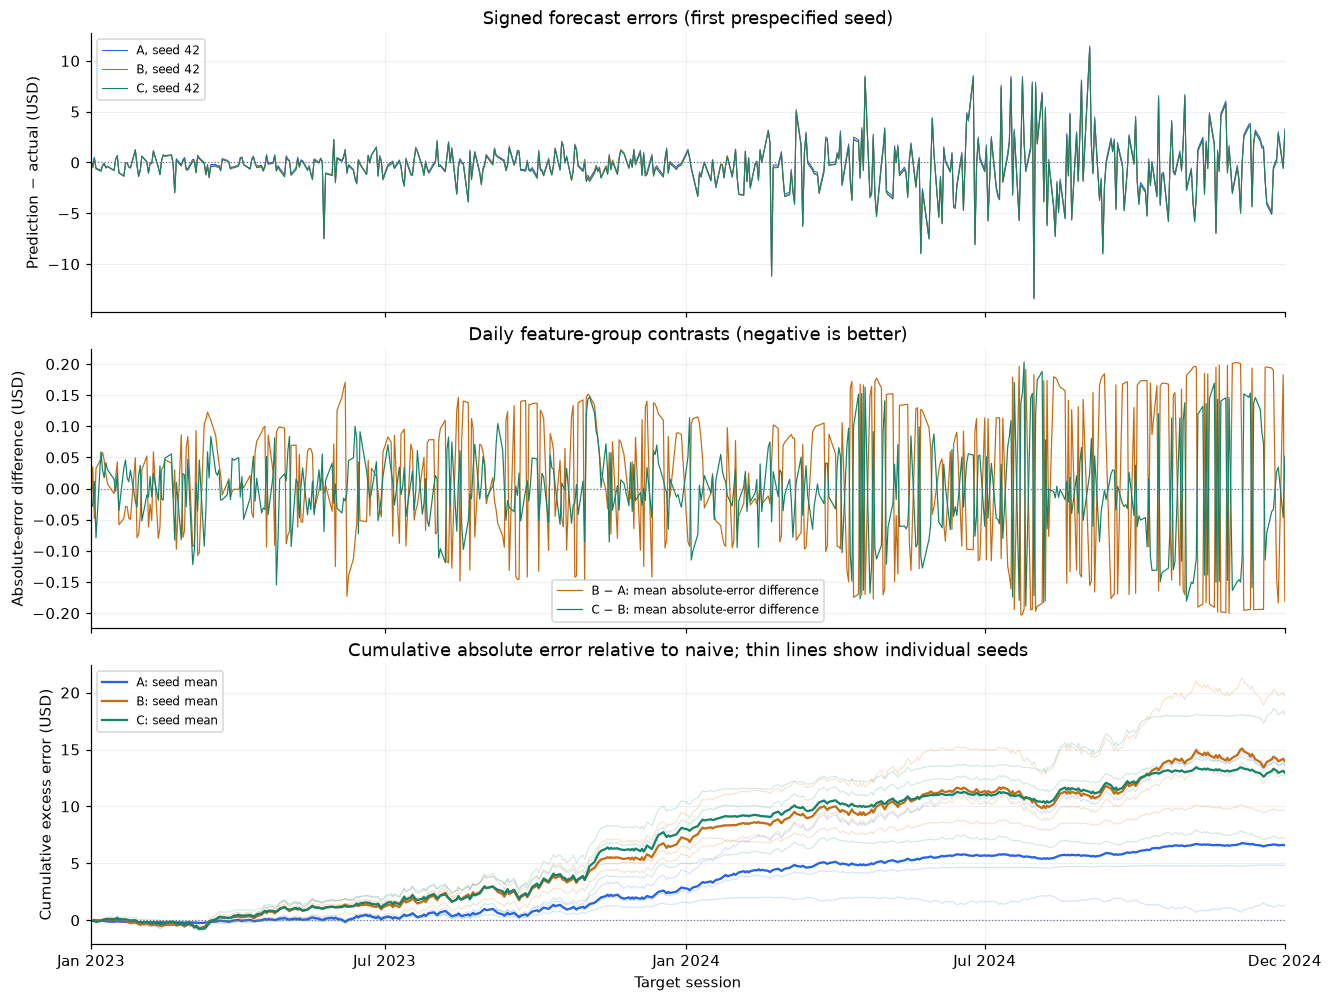

In [16]:
annual_runs=[];annual_summary=[]
for year in sorted(dates.dt.year.unique()):
    mask=dates.dt.year.eq(year).to_numpy()
    for run in runs:
        key=(run["variant"],run["seed"])
        metrics=error_metrics(truth[mask],predictions[key][mask])
        for metric in ["mae_usd","rmse_usd"]:
            np.testing.assert_allclose(metrics[metric],run["by_year"][str(year)][metric],rtol=0,atol=1e-7)
        annual_runs.append({"year":year,"variant":key[0],"seed":key[1],**metrics})
    for variant in VARIANTS:
        grouped_year=aggregate([r for r in annual_runs if r["year"]==year and r["variant"]==variant])
        for metric in ["mae_usd","rmse_usd"]:
            for statistic in ["mean","std"]:
                np.testing.assert_allclose(grouped_year[metric][statistic],results["annual_aggregate"][str(year)][variant][metric][statistic],rtol=0,atol=1e-7)
        annual_summary.append({"year":year,"model":variant,"n":int(mask.sum()),
                               "MAE mean":grouped_year["mae_usd"]["mean"],"MAE SD":grouped_year["mae_usd"]["std"],
                               "RMSE mean":grouped_year["rmse_usd"]["mean"],"RMSE SD":grouped_year["rmse_usd"]["std"]})
    for name,pred in [("naive",naive),("arima",arima_saved.arima_prediction.to_numpy())]:
        metrics=error_metrics(truth[mask],pred[mask])
        for metric in ["mae_usd","rmse_usd"]:np.testing.assert_allclose(metrics[metric],results["annual_baselines"][str(year)][name][metric],rtol=0,atol=1e-7)
        annual_summary.append({"year":year,"model":name,"n":metrics["n"],"MAE mean":metrics["mae_usd"],"MAE SD":np.nan,"RMSE mean":metrics["rmse_usd"],"RMSE SD":np.nan})
display(pd.DataFrame(annual_summary).sort_values(["year","model"]))
display(pd.DataFrame(annual_runs))
fig,axes=plt.subplots(3,1,figsize=(12,9),layout="constrained",sharex=True)
for variant in VARIANTS:
    axes[0].plot(dates,predictions[(variant,42)]-truth,color=COLORS[variant],lw=.7,label=f"{variant}, seed 42")
    cumulative=[]
    for seed in SEEDS:
        excess=np.abs(predictions[(variant,seed)]-truth)-np.abs(naive-truth)
        cumulative.append(np.cumsum(excess))
        axes[2].plot(dates,cumulative[-1],color=COLORS[variant],alpha=.2,lw=.7)
    axes[2].plot(dates,np.mean(cumulative,axis=0),color=COLORS[variant],label=f"{variant}: seed mean")
for contrast,color in [(('B','A'),COLORS['B']),(('C','B'),COLORS['C'])]:
    lhs,rhs=contrast
    differences=np.stack([np.abs(predictions[(lhs,s)]-truth)-np.abs(predictions[(rhs,s)]-truth) for s in SEEDS])
    axes[1].plot(dates,differences.mean(axis=0),color=color,lw=.8,label=f"{lhs} − {rhs}: mean absolute-error difference")
axes[0].set(title="Signed forecast errors (first prespecified seed)",ylabel="Prediction − actual (USD)")
axes[1].set(title="Daily feature-group contrasts (negative is better)",ylabel="Absolute-error difference (USD)")
axes[2].set(title="Cumulative absolute error relative to naive; thin lines show individual seeds",ylabel="Cumulative excess error (USD)",xlabel="Target session")
for ax in axes:
    ax.axhline(0,color="#64748b",ls=":",lw=.8);ax.legend(fontsize=8)
    ax.set_xlim(dates.iloc[0],dates.iloc[-1])
# Explicit development-period ticks prevent an automatic tick beyond the observed endpoint.
axes[-1].set_xticks(pd.to_datetime(["2023-01-03","2023-07-01","2024-01-01","2024-07-01","2024-12-31"]))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

**RQ2:** Adding the technical group increases mean validation MAE from **\$1.702599972 to \$1.717303573**, a paired mean change of **+\$0.014703600 (+0.864%)**. Seed 123 improves slightly; the other two worsen. Thus the group does not improve average performance under this protocol. The experiment does not identify why or which indicator is responsible.

**RQ3:** Adding context reduces mean MAE from B to C by **\$0.001998672 (0.116%)**. Two seeds improve and one worsens. C remains worse than A, and C's annual mean is worse than B in 2023 but better in 2024. This small, variable result does not establish a reliable market-context advantage.

All nine runs have higher **full-period** MAE and RMSE than naïve. A has the lowest mean LSTM error in both years. A/seed42 does slightly beat naïve within 2024 alone, so an overall conclusion must not be extended to every subset. Annual dollar errors are much larger in 2024. The cumulative panels aggregate forecast errors—not wealth, returns or trading profit. Seed means are summaries of metrics, not ensemble forecasts.

## 14. Critical analysis and methodological limitations

**Redundant representations.** Correlations below use unique fitting input rows, avoiding artificial repetition from windows. Moreover, the two EMA distances determine relative MACD algebraically:
\[
\frac{MACD}{C}=\frac{1}{1+d_{EMA12}}-\frac{1}{1+d_{EMA26}}.
\]
This exact relationship demonstrates dependence, not that MACD should be removed: an explicit nonlinear transformation could still help a finite network learn. A grouped comparison cannot establish individual importance.

**Scale and distribution shift.** Derived ratios are invariant to multiplying the complete price history by a constant; that is different from invariance to changing regimes, momentum or volatility. Absolute NVDA Close remains an input in every variant. Dollar-correction targets also retain price-scale dependence. We examine fitted versus validation-origin distributions without changing the transformations or tuning feature definitions on validation.

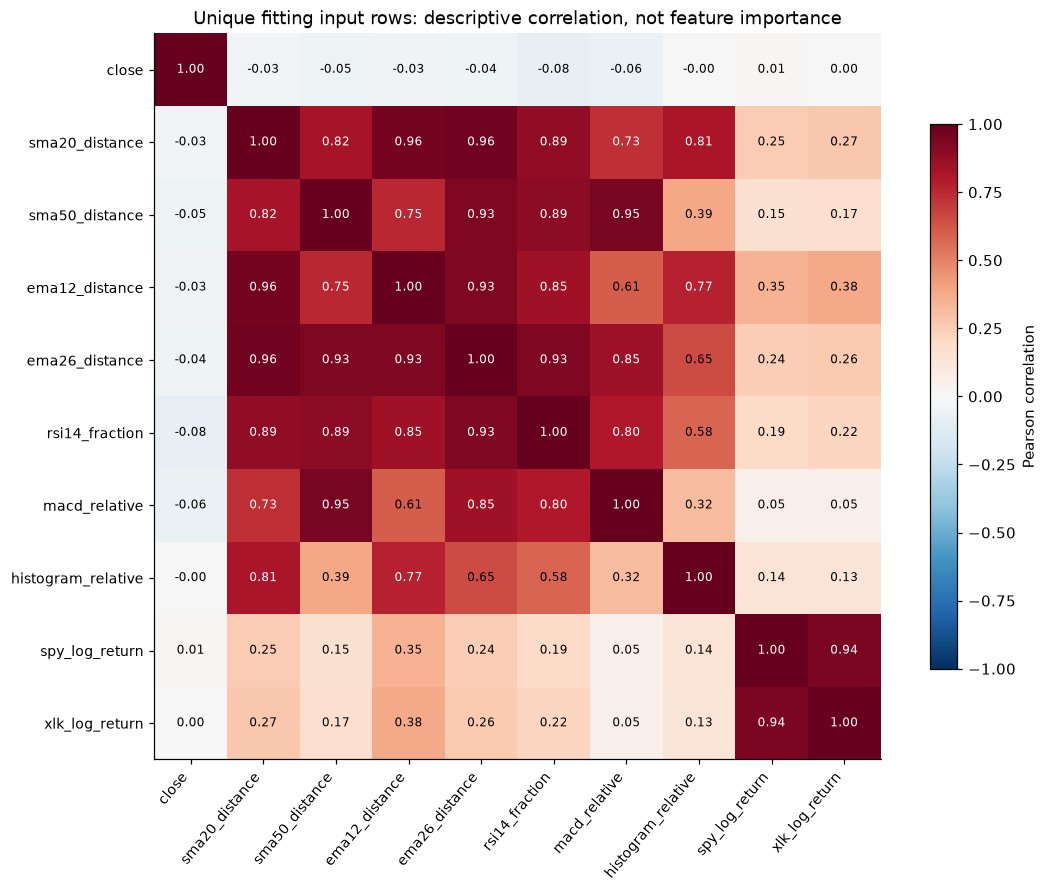

Relative MACD is exactly determined by EMA distances (within floating-point tolerance).


,fitting minimum,fitting maximum,validation-origin minimum,validation-origin maximum,origins outside fitting range (%),validation-origin mean z,maximum absolute z
feature,,,,,,,
close,0.482750,33.375999,14.265000,148.880005,80.079681,8.526396,18.764919
sma20_distance,-0.277389,0.267464,-0.152224,0.301241,0.597610,0.347275,3.929511
sma50_distance,-0.391218,0.374092,-0.178246,0.419109,0.796813,0.556550,3.145592
ema12_distance,-0.240734,0.218520,-0.107088,0.215868,0.000000,0.313822,4.459048
ema26_distance,-0.304758,0.258621,-0.135355,0.291384,0.597610,0.452323,3.757861
rsi14_fraction,0.188295,0.891697,0.313938,0.852591,0.000000,0.275996,2.285501
macd_relative,-0.153989,0.075315,-0.052252,0.079161,0.796813,0.489556,2.053488
histogram_relative,-0.041388,0.027009,-0.024725,0.025864,0.000000,0.012041,2.627970
spy_log_return,-0.115887,0.086731,-0.030257,0.024561,0.000000,0.045049,2.571249


,year,dollar-change SD USD,percentage-return SD (percentage points)
0,2022,0.766600,3.982006
1,2023,1.015345,3.050845
2,2024,3.500495,3.307395


In [17]:
correlation=unique[VARIANTS["C"]].corr()
fig,ax=plt.subplots(figsize=(10.5,8),layout="constrained")
im=ax.imshow(correlation,cmap="RdBu_r",vmin=-1,vmax=1);ax.grid(False)
ax.set_xticks(range(10),correlation.columns,rotation=50,ha="right",fontsize=9)
ax.set_yticks(range(10),correlation.columns,fontsize=9)
for i in range(10):
    for j in range(10):
        value=correlation.iloc[i,j]
        ax.text(j,i,f"{value:.2f}",ha="center",va="center",fontsize=8,color="white" if abs(value)>.65 else "black")
ax.set_title("Unique fitting input rows: descriptive correlation, not feature importance")
fig.colorbar(im,ax=ax,shrink=.75,label="Pearson correlation");plt.show()
identity=1/(1+features.ema12_distance)-1/(1+features.ema26_distance)
np.testing.assert_allclose(identity,features.macd_relative,rtol=0,atol=1e-14,equal_nan=True)
print("Relative MACD is exactly determined by EMA distances (within floating-point tolerance).")

# Constant-rescaling verification uses training observations only and fits no model.
scaled_train={ticker:s.loc[:config["train_end"]]*10 for ticker,s in series.items()}
_,scaled_features=calculate_features(scaled_train,dict(config,validation_end=config["train_end"]))
np.testing.assert_allclose(scaled_features.iloc[:,1:],train_features.iloc[:,1:],rtol=1e-10,atol=1e-12,equal_nan=True)
origin_dates=reference.metadata.loc[evaluate,"origin_date"]
validation_inputs=features.loc[origin_dates,VARIANTS["C"]]
shift_rows=[]
for name in VARIANTS["C"]:
    values=validation_inputs[name]
    parameters=prepared["C"].provenance["input_scalers"][name]
    z=Standardisation(**parameters).transform(values)
    shift_rows.append({"feature":name,"fitting minimum":unique[name].min(),"fitting maximum":unique[name].max(),
                       "validation-origin minimum":values.min(),"validation-origin maximum":values.max(),
                       "origins outside fitting range (%)":100*((values<unique[name].min())|(values>unique[name].max())).mean(),
                       "validation-origin mean z":z.mean(),"maximum absolute z":np.abs(z).max()})
display(pd.DataFrame(shift_rows).set_index("feature"))
price=series["NVDA"]
volatility_rows=[]
for year in (2022,2023,2024):
    start,end=f"{year}-01-01",f"{year}-12-31"
    volatility_rows.append({"year":year,"dollar-change SD USD":price.diff().loc[start:end].std(),
                            "percentage-return SD (percentage points)":(price.pct_change(fill_method=None)*100).loc[start:end].std()})
display(pd.DataFrame(volatility_rows))

SMA20 distance correlates approximately **0.957 with EMA12 distance**, **0.964 with EMA26 distance**, and **0.891 with RSI** on the fitting rows. SPY/XLK feature correlation is approximately **0.939**. These values confirm substantial shared variation, not a causal explanation of the forecast ranking.

The distribution table quantifies where training-standardised inputs encounter new ranges. Price-relative features reduce direct level dependence, but do not erase the absolute Close channel or the dollar target. Dollar-change SD rises from about **\$1.015 in 2023 to \$3.500 in 2024**, while percentage-return SD changes from **3.051 to 3.307 percentage points**. These observations agree with the scale concerns in Notebooks 01 and 04, without proving stationarity or gate saturation.

**Interpretation limits and implementation assessment.** The calculation, alignment, scaling and checkpoint checks support retaining the current numerical implementation. Lower fitting MSE for B/C fails to improve mean validation error; this is a generalisation limitation, but no unique overfitting onset or cause is established. Additional features also increase parameters and effective historical context. Minimum warm-up retains some recursive seed dependence. Three seeds, fixed parameters, a single development interval and no interaction search limit generalisation.

The optional return-target formulation \(\widehat C_{t+1}=C_t(1+\widehat r_{t+1})\) remains a **separate proposal requiring approval**. It would change loss weighting as well as reconstruction, require new target scalers and controlled paired comparisons, and need consistent repetition across feature variants if adopted. It is not introduced here, nor selected because it might beat persistence. No indicator is removed, no epoch is changed and no recorded result is overwritten on these diagnostics.

## 15. Research findings and conclusions

The evidence supports the following answers:

- **Construction:** SMA windows and arithmetic EMA seeds, Wilder RSI, MACD/signal/histogram identities and context log returns agree with mathematical checks. The actual feature lists contain 1, 8 and 10 inputs; the MACD signal is not separately included.
- **Temporal design:** all variants share the 49-row warm-up, 1,935 fitting examples and 502 validation dates. Calendar, prefix, future-perturbation and input/target checks support causal construction. Scalers use unique fitting inputs and fitting labels only.
- **Inference:** all nine saved checkpoints reproduce the recorded forecasts and metrics through the actual residual reconstruction. Fixed architecture settings produce 1,169 / 1,617 / 1,745 trainable parameters.
- **RQ2:** the technical bundle does not improve average forecasting performance over the common-sample price-only reference.
- **RQ3:** context offers a small average improvement over the technical model, with seed and year dependence; it does not beat the price-only control on mean error.
- **Benchmark:** no feature-enhanced run beats naïve on full-period MAE or RMSE. This does not establish that feature engineering is universally ineffective, that individual indicators are useless, or that market context cannot be predictive under another justified protocol.

The 2023–2024 period is development evidence. Its repeated analysis must not be presented as an untouched final assessment. An independent 2025 evaluation requires explicit approval of the frozen methodology; this notebook neither freezes that choice nor accesses the test period.

In [18]:
checks={
    "three explicitly bounded source intervals":all(s.index.max()<=pd.Timestamp(config["validation_end"]) for s in series.values()),
    "feature names and order match protocol":protocol["variants"]==VARIANTS,
    "common fit/evaluation counts 1935/502":(int(fit.sum()),int(evaluate.sum()))==(1935,502),
    "input widths 1/8/10": [prepared[v].X.shape[2] for v in VARIANTS]==[1,8,10],
    "saved eligibility and scalers reproduced":all(d.provenance==results["eligibility"][v] for v,d in prepared.items()),
    "all nine checkpoints verified":len(verification)==9,
    "checkpoint discrepancy below one microdollar":bool((verification["max prediction discrepancy USD"]<1e-6).all()),
    "all forecasts share 502 targets":len(dates)==502,
    "19 fixed epochs and 1159 updates each":all(r["epochs_completed"]==19 and r["optimizer_steps"]==1159 for r in runs),
}
assert all(checks.values())
display(pd.Series(checks,name="Verification passed"))
print("No model-training call, additional experiment or reserved-period evaluation is performed.")

three explicitly bounded source intervals       True
feature names and order match protocol          True
common fit/evaluation counts 1935/502           True
input widths 1/8/10                             True
saved eligibility and scalers reproduced        True
all nine checkpoints verified                   True
checkpoint discrepancy below one microdollar    True
all forecasts share 502 targets                 True
19 fixed epochs and 1159 updates each           True
Name: Verification passed, dtype: bool

No model-training call, additional experiment or reserved-period evaluation is performed.
